# Oman Real Estate Market Analysis
## Exploratory analysis of uploaded real estate records

**2022 land snapshots · October 2024 service-coded records · January–September 2025 Muscat brokerage**

A reproducible portfolio analysis of 28,558 uploaded source record occurrences. The 2020–2026 window is a coverage objective; the files do not constitute a continuous annual series. No prices, monetary conclusions or missing periods are inferred.

**Metric:** retained source rows, not independently identified transactions. Exact visible-row repeats remain because transaction IDs are absent.

**Navigate:** [provenance](#Provenance-and-reproducibility) · [coverage](#Coverage-before-comparison) · [2022-land](#Two-comparable-2022-land-snapshots) · [2024-land](#October-2024-service-coded-snapshot) · [attributes](#Buyer-type-and-ownership-attributes) · [Muscat](#Muscat-brokerage-registrations) · [interpretation](#Interpretation-and-next-actions).

## Provenance and reproducibility

Latest base `main`: `2c4237a`, containing merged PR #4. Input audit run: `71008482abd46aa7f0bc`. Exact input manifest, artifacts and original workbook hashes are checked before analysis. Read `docs/eda_methodology.md`, `docs/data_sources.md` and `docs/uploaded_source_registry.json` for attribution and unresolved provenance.

Muscat has embedded MOHUP attribution; land workbook source URLs/licences remain pending. This analysis inherits those explicit limits. Three incorrect XLSX dimensions were repaired by the prior audit without resaving originals. Arabic shaping is used only for figure display; source labels and grouping keys remain unchanged.

Run from the repository root with `python -m src.run_eda`. Every displayed chart/table comes from the same generated run. Power BI uses separate monthly fact tables and shared observed dimensions; it must not sum the three definitions into one national sales measure.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "docs/eda_config.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.eda_analysis import load_inputs, summarize
from src.run_eda import run

analysis = run(execute_notebook=False)
assert analysis["run_id"] == "168665c92a8a2ff91598", "Notebook/code/runtime changed: regenerate with python -m src.run_eda"
inputs = load_inputs()
tables = summarize(inputs)
FIGURES = ROOT / analysis["figures_directory"]
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
def show_figure(name):
    display(Image(filename=str(FIGURES / (name + ".png")), width=1100))
display(tables["dataset_summary"])
print("Input hashes verified; record occurrences preserved; no monetary calculations.")

,dataset_id,scope_id,reported_record_count,first_record_date,last_record_date,observed_months,observed_governorates,observed_wilayat_labels,nonstandard_wilayat_rows
0,land_dec_2022,land_buy_sell_2022,5667,2022-12-04,2022-12-29,1,11,61,1
1,land_nov_2022,land_buy_sell_2022,7501,2022-11-01,2022-11-29,1,11,62,1
2,land_oct_2024,land_service_coded_2024,6024,2024-10-01,2024-10-31,1,11,63,0
3,muscat_brokerage_2025,muscat_brokerage_registration_2025,9366,2025-01-02,2025-09-30,9,1,6,0


Input hashes verified; record occurrences preserved; no monetary calculations.


## Coverage before comparison

All eleven modern governorates are represented in each supplied land month after documented wilayat-based resolution of the combined Sharqiyah label. The brokerage file covers six Muscat wilayats only. Coverage is presence of uploaded records, not proof of full market capture. Grey chart cells are unavailable/outside scope, not zero activity. No uploaded 2020, 2021, 2023 or 2026 records exist.

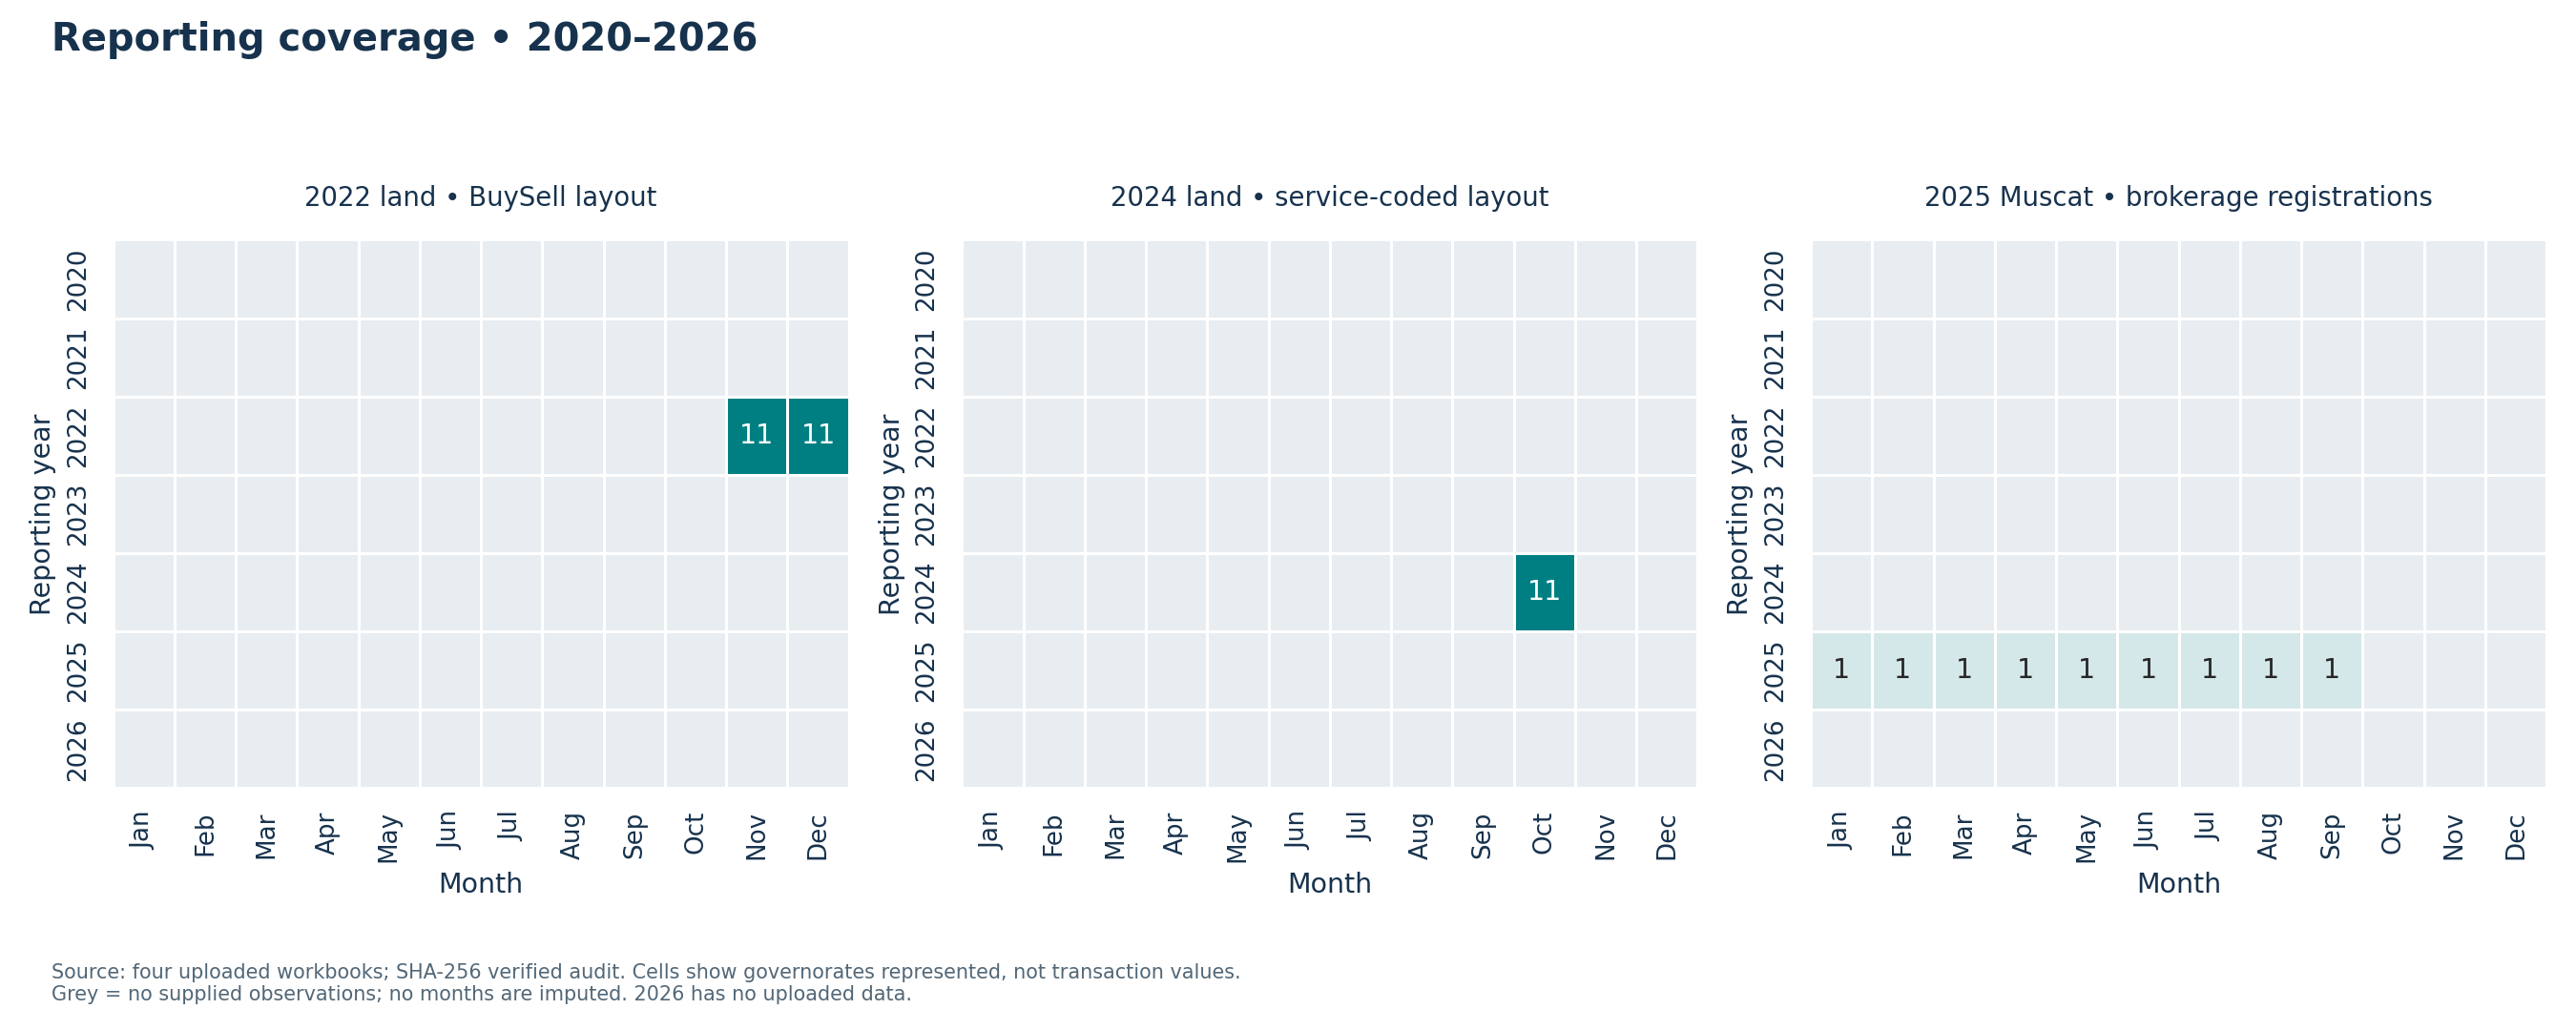

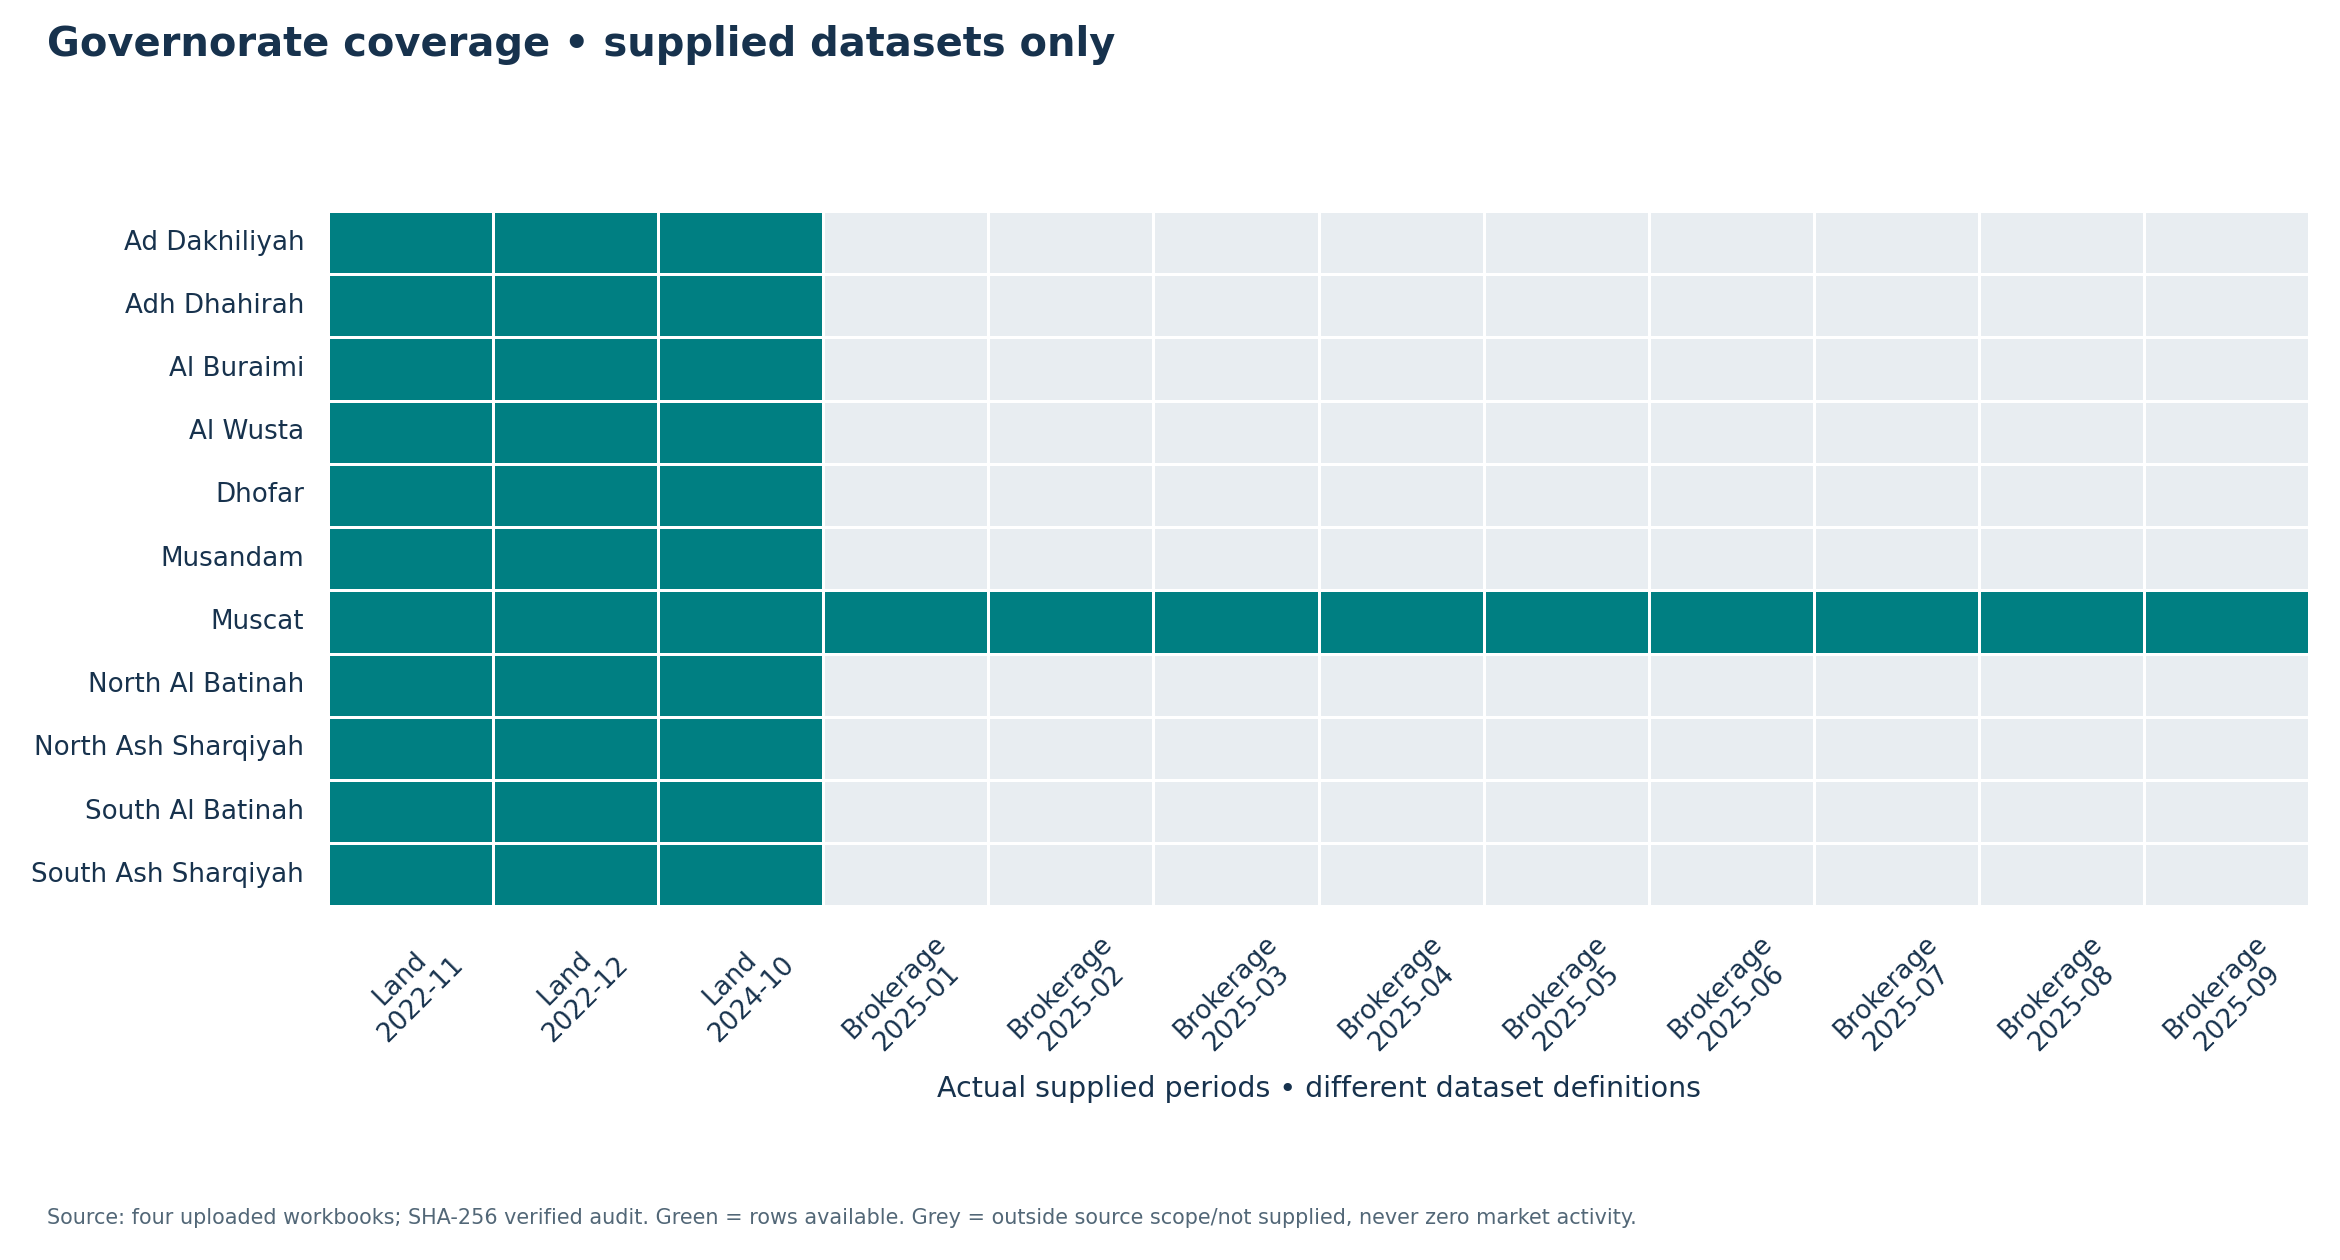

,dataset_id,scope_id,period_id,governorate_id,reported_record_count
0,land_dec_2022,land_buy_sell_2022,2022-12,ad_dakhiliyah,1075
1,land_dec_2022,land_buy_sell_2022,2022-12,adh_dhahirah,208
2,land_dec_2022,land_buy_sell_2022,2022-12,al_buraimi,196
3,land_dec_2022,land_buy_sell_2022,2022-12,al_wusta,294
4,land_dec_2022,land_buy_sell_2022,2022-12,dhofar,432
5,land_dec_2022,land_buy_sell_2022,2022-12,musandam,23
6,land_dec_2022,land_buy_sell_2022,2022-12,muscat,734
7,land_dec_2022,land_buy_sell_2022,2022-12,north_al_batinah,760
8,land_dec_2022,land_buy_sell_2022,2022-12,north_ash_sharqiyah,706
9,land_dec_2022,land_buy_sell_2022,2022-12,south_al_batinah,909


In [2]:
show_figure("coverage_calendar")
show_figure("coverage_governorates")
display(tables["coverage_observed"])

## Two comparable 2022 land snapshots

November and December share the observed BuySell schema. Compare counts and composition within those two files; completeness and unique transaction identity remain unverified. Percentage points measure geographic share change; percentage changes describe row counts, not prices or annual market growth.

Wilayat charts rank only standard labels. Two source rows labelled الساحل الشرقي under Dhofar are retained in governorate totals and exported tables but excluded from wilayat ranking. Rankings cover observed labels and do not establish a complete administrative inventory.

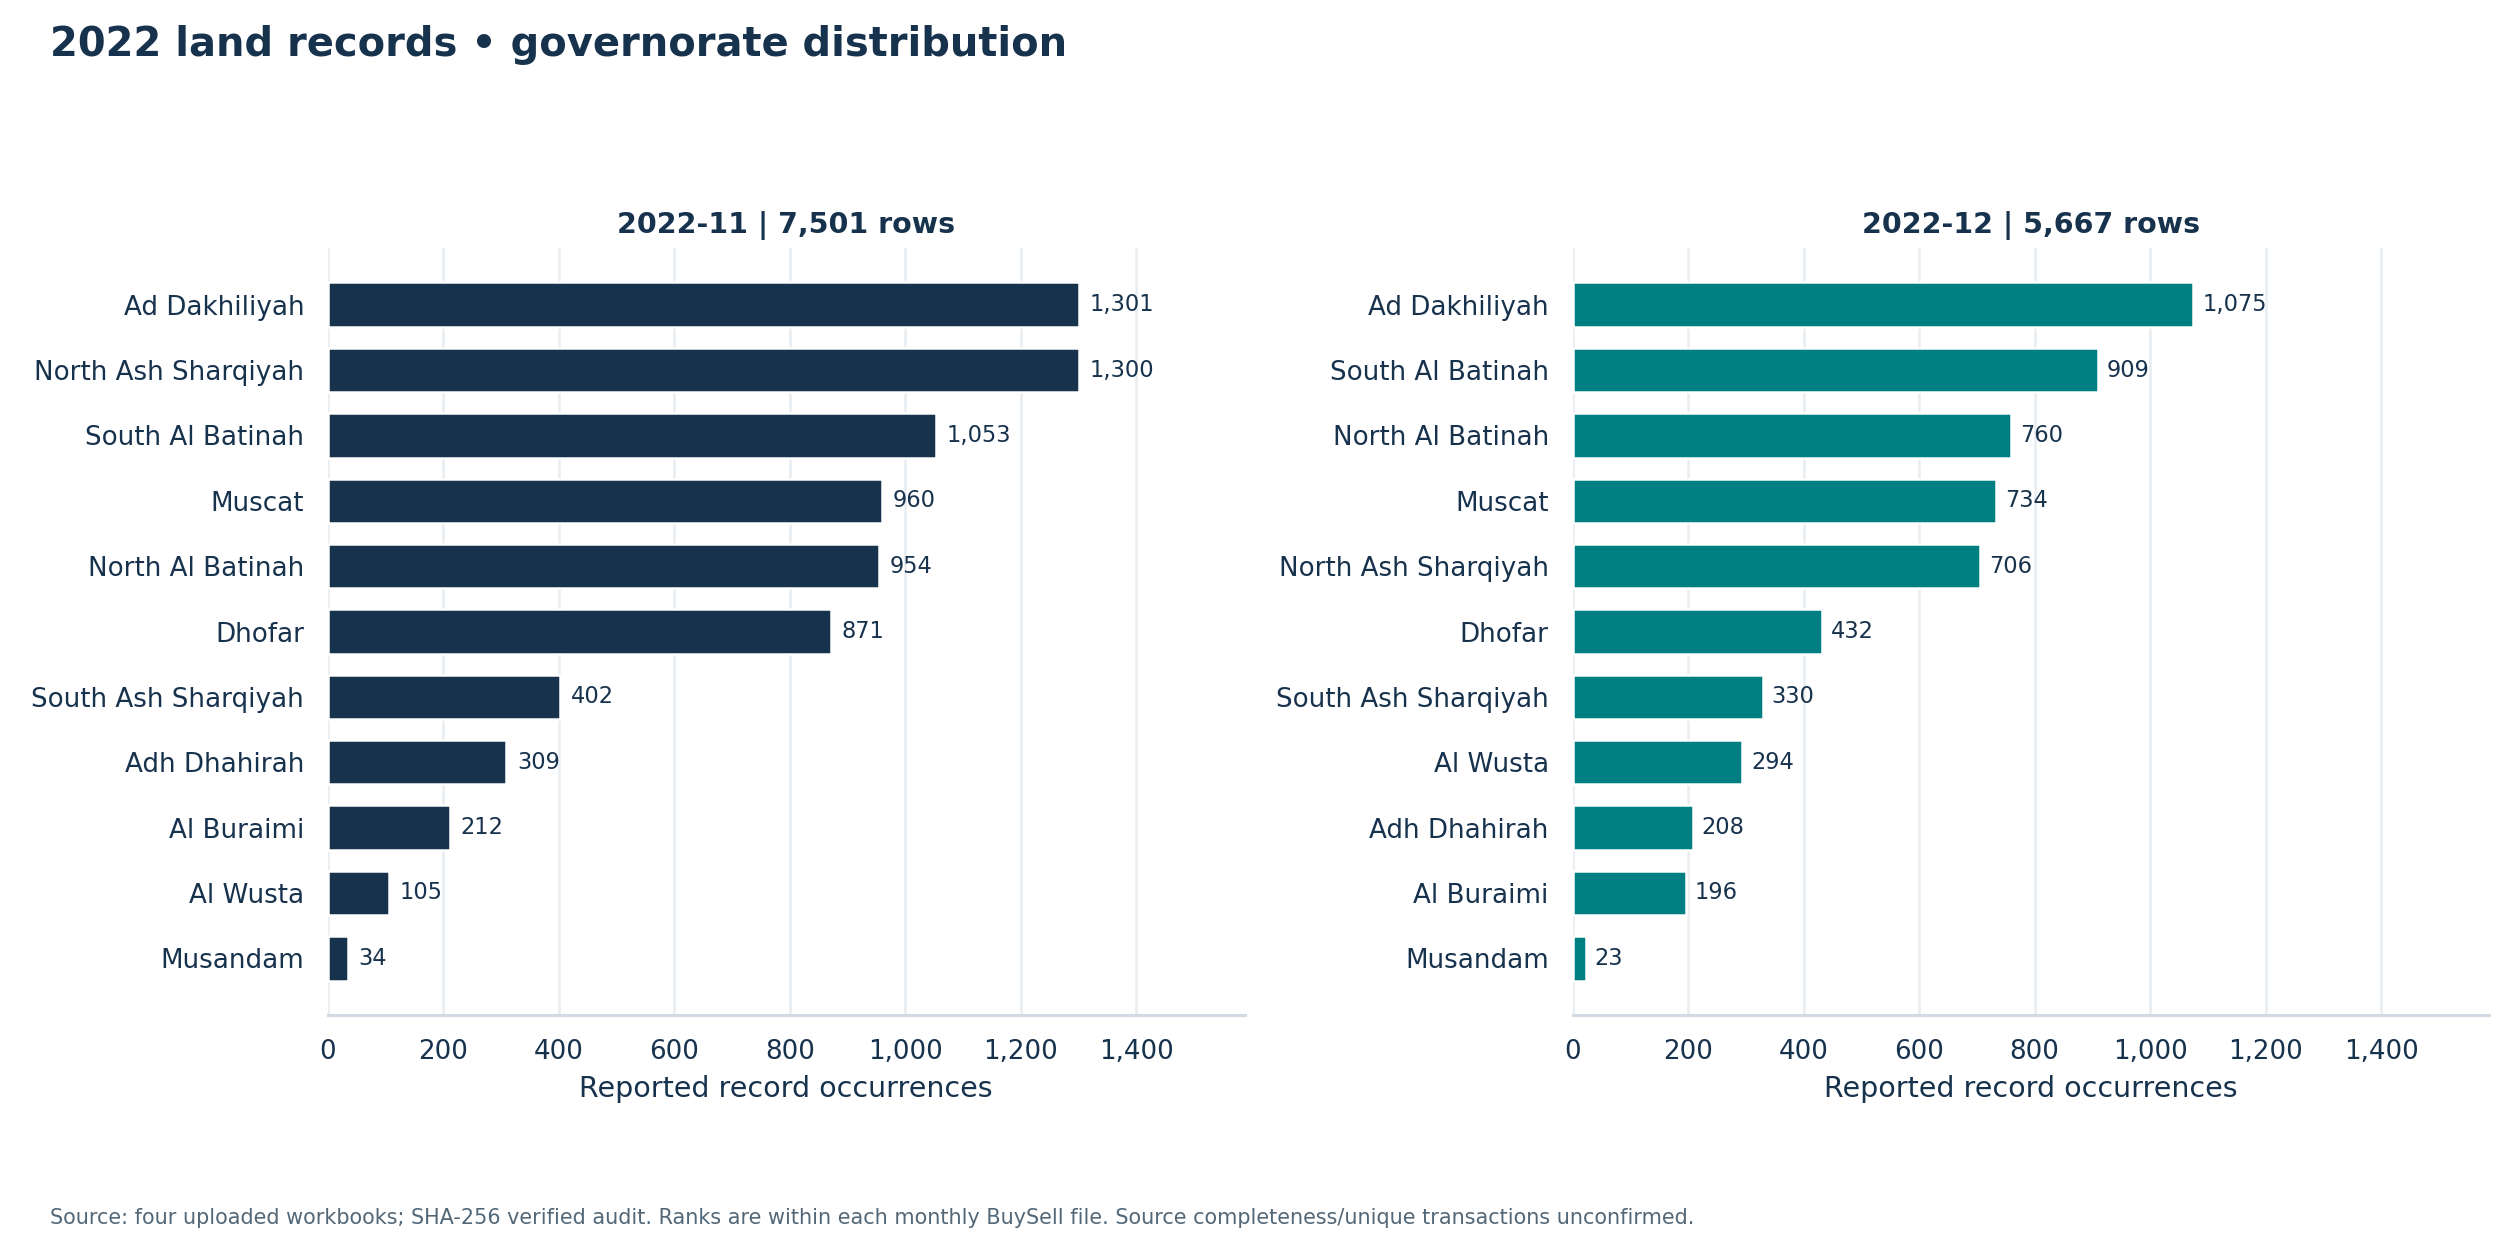

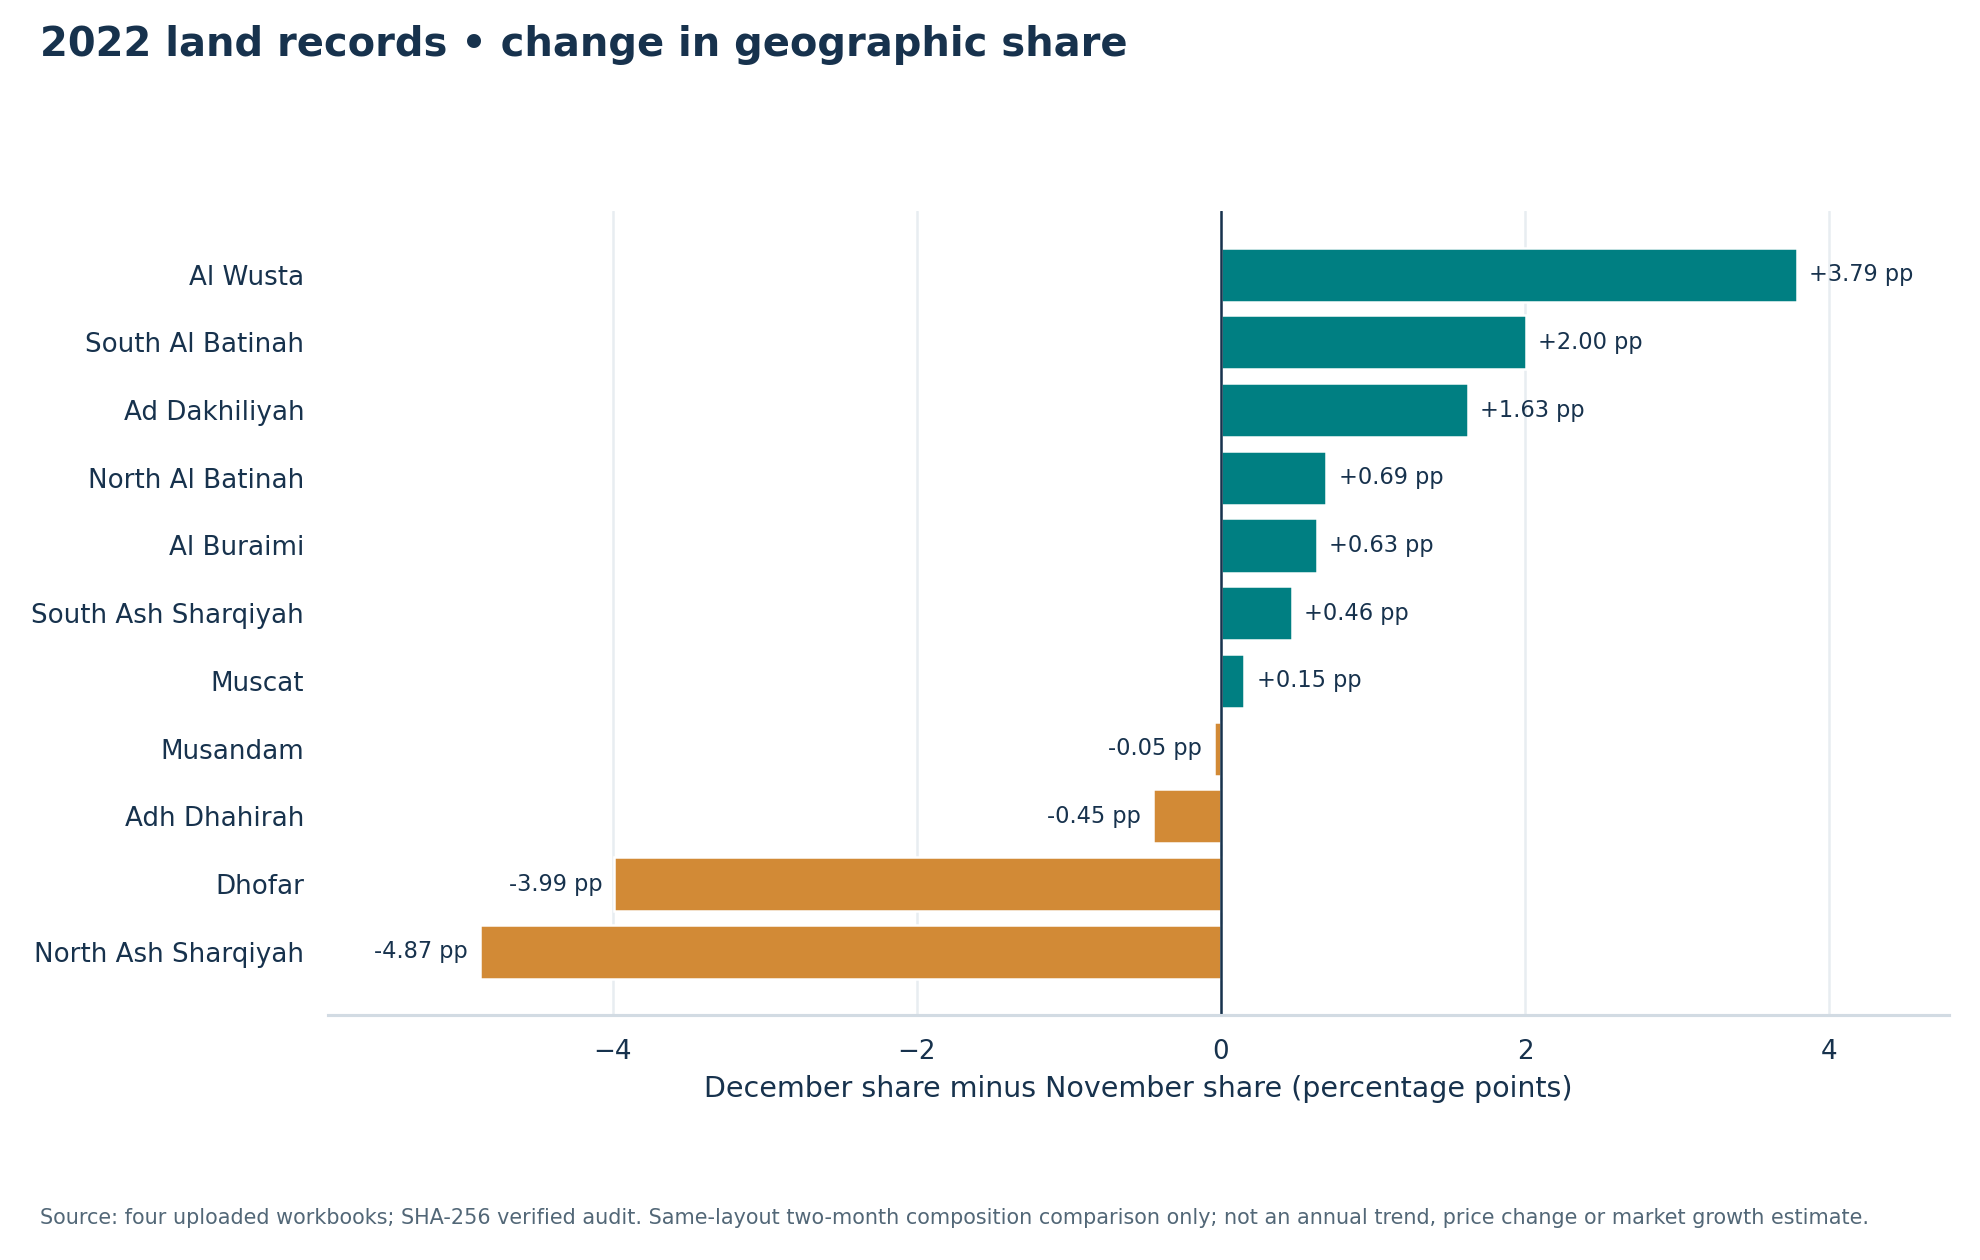

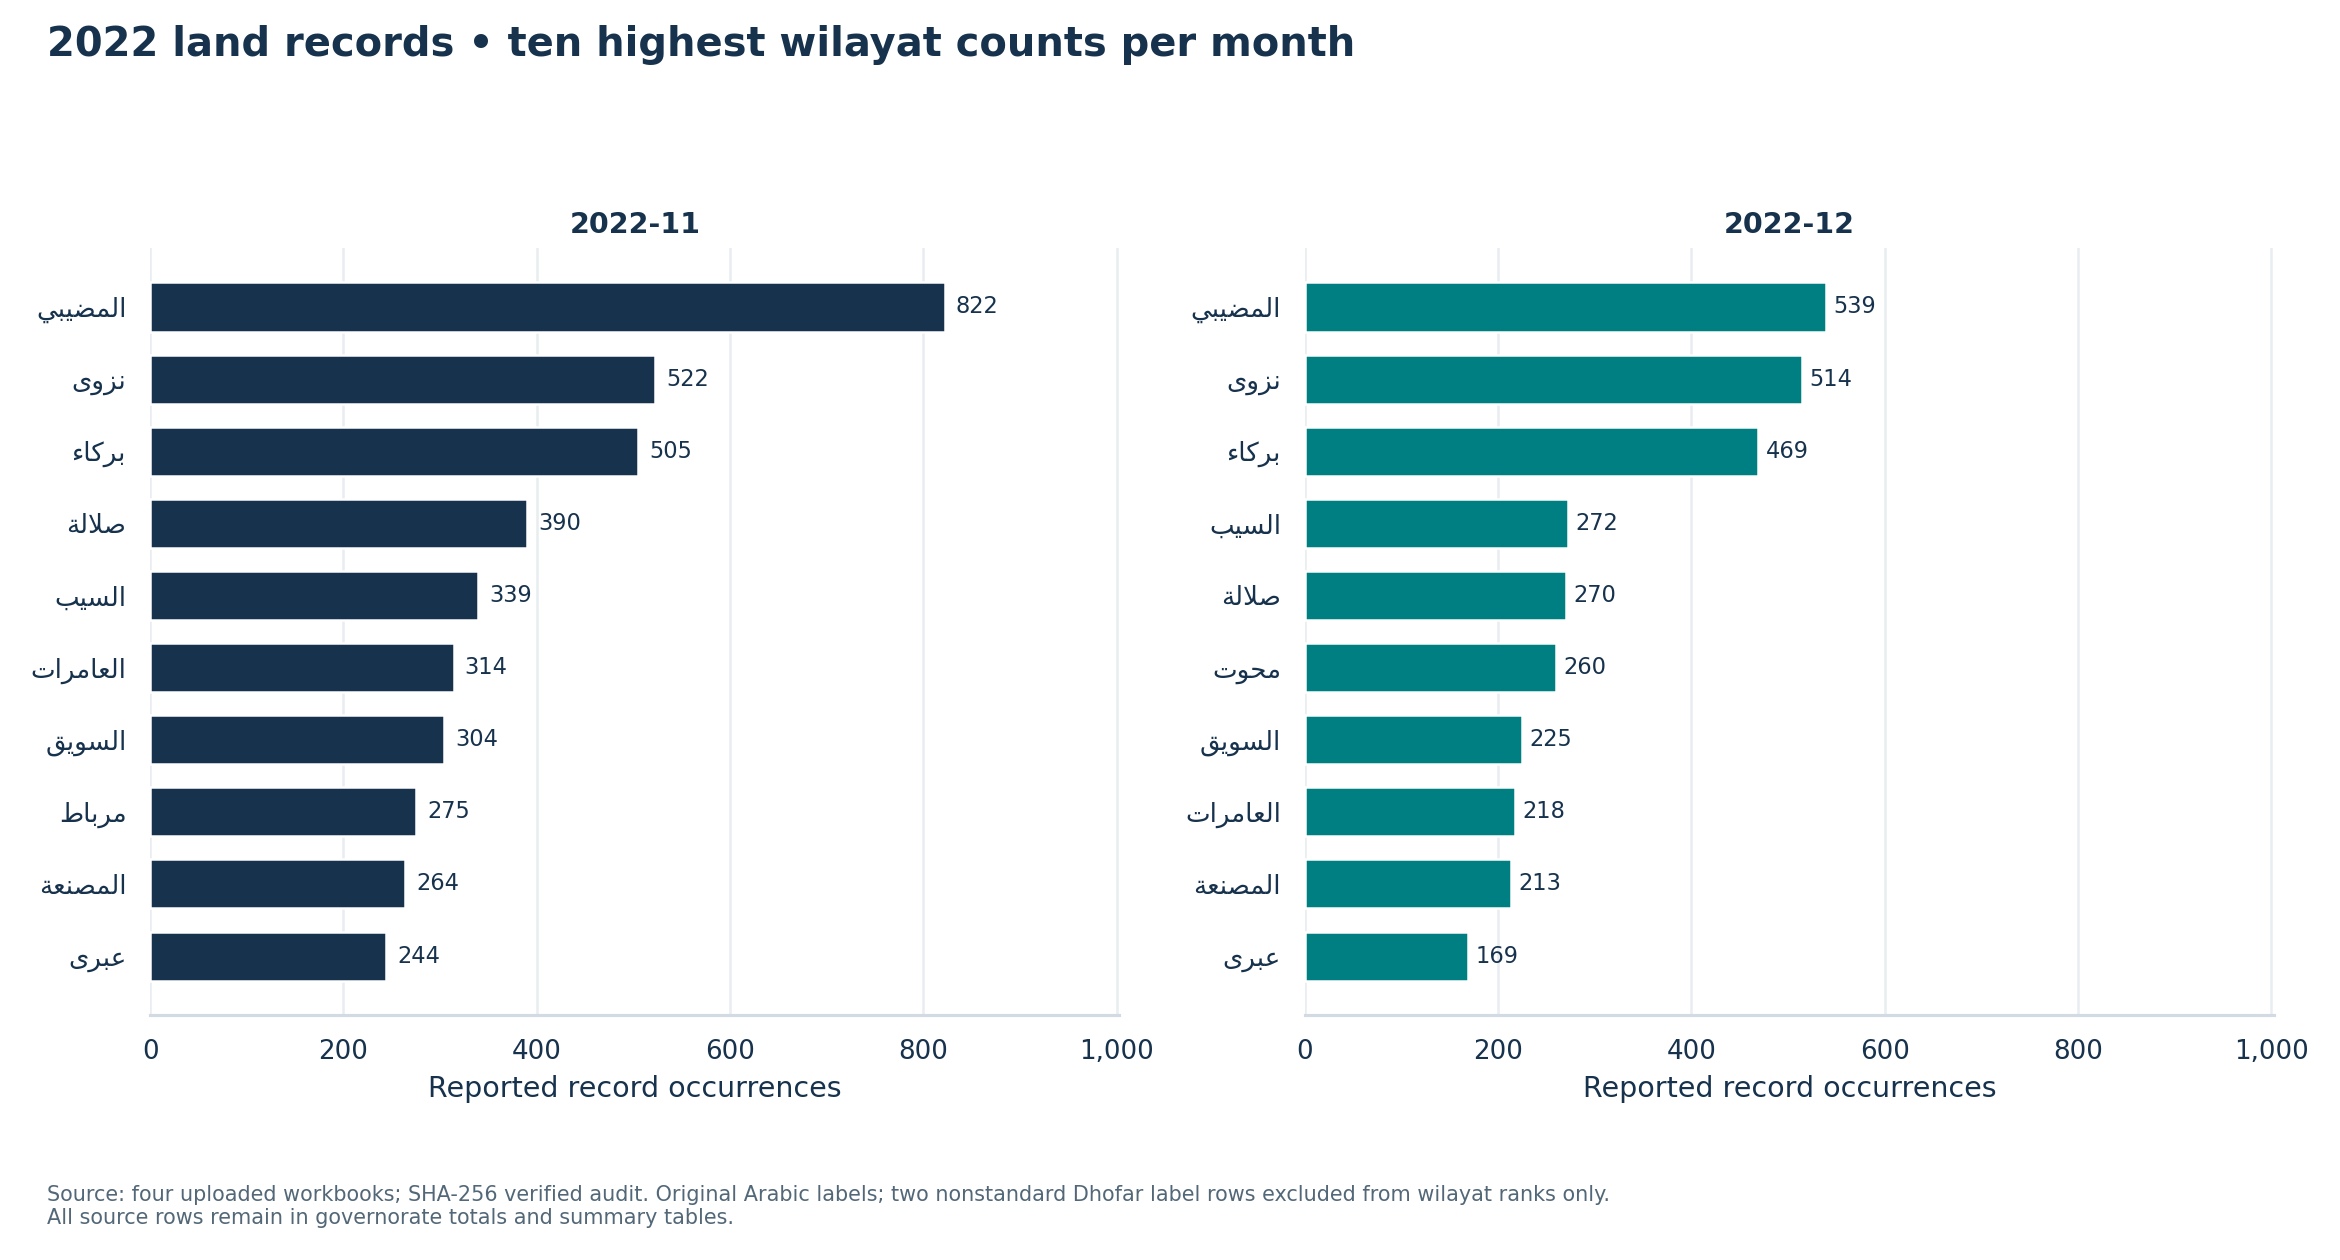

,governorate_id,governorate_en,governorate_ar,november_records,november_share_pct,december_records,december_share_pct,record_count_difference,record_count_change_pct,share_change_percentage_points,comparison_scope
0,ad_dakhiliyah,Ad Dakhiliyah,الداخلية,1301,17.34,1075,18.97,-226,-17.37,1.63,land_buy_sell_2022
8,north_ash_sharqiyah,North Ash Sharqiyah,شمال الشرقية,1300,17.33,706,12.46,-594,-45.69,-4.87,land_buy_sell_2022
9,south_al_batinah,South Al Batinah,جنوب الباطنة,1053,14.04,909,16.04,-144,-13.68,2.00,land_buy_sell_2022
6,muscat,Muscat,مسقط,960,12.80,734,12.95,-226,-23.54,0.15,land_buy_sell_2022
7,north_al_batinah,North Al Batinah,شمال الباطنة,954,12.72,760,13.41,-194,-20.34,0.69,land_buy_sell_2022
4,dhofar,Dhofar,ظفار,871,11.61,432,7.62,-439,-50.40,-3.99,land_buy_sell_2022
10,south_ash_sharqiyah,South Ash Sharqiyah,جنوب الشرقية,402,5.36,330,5.82,-72,-17.91,0.46,land_buy_sell_2022
1,adh_dhahirah,Adh Dhahirah,الظاهرة,309,4.12,208,3.67,-101,-32.69,-0.45,land_buy_sell_2022
2,al_buraimi,Al Buraimi,البريمي,212,2.83,196,3.46,-16,-7.55,0.63,land_buy_sell_2022
3,al_wusta,Al Wusta,الوسطى,105,1.40,294,5.19,189,180.00,3.79,land_buy_sell_2022


In [3]:
show_figure("land_2022_governorates")
show_figure("land_2022_share_change")
show_figure("land_2022_wilayats")
display(tables["governorate_nov_dec_2022"].sort_values("november_records", ascending=False))

## October 2024 service-coded snapshot

Analyze this layout separately. RN13A and RN13C are verified as observed source codes; their meanings are unverified, so neither is relabelled as sales, mortgages or another transaction class. RE_VALUE units remain unverified and the analytical facts deliberately exclude amounts. Amount presence is a data-quality attribute only.

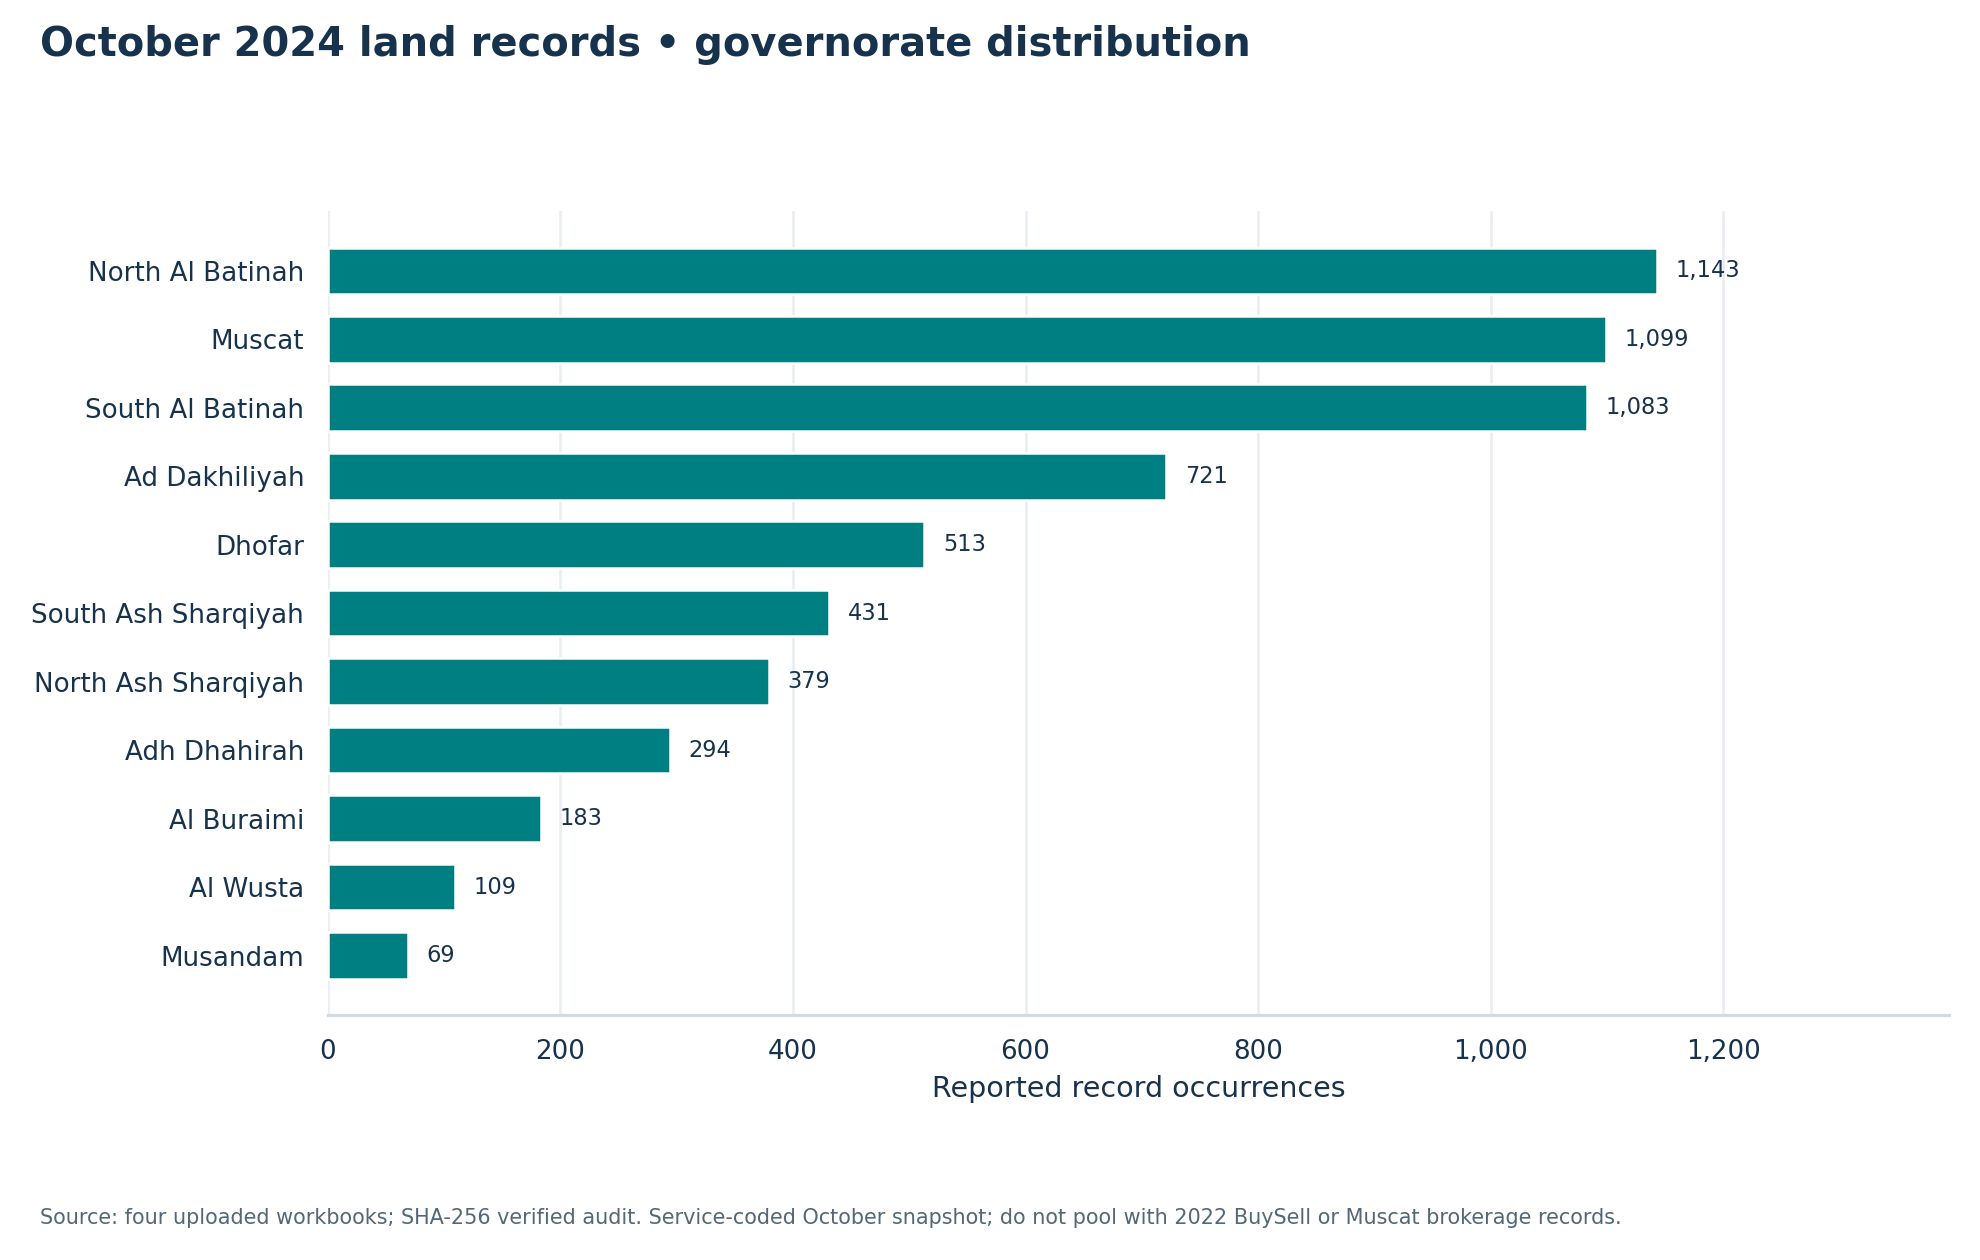

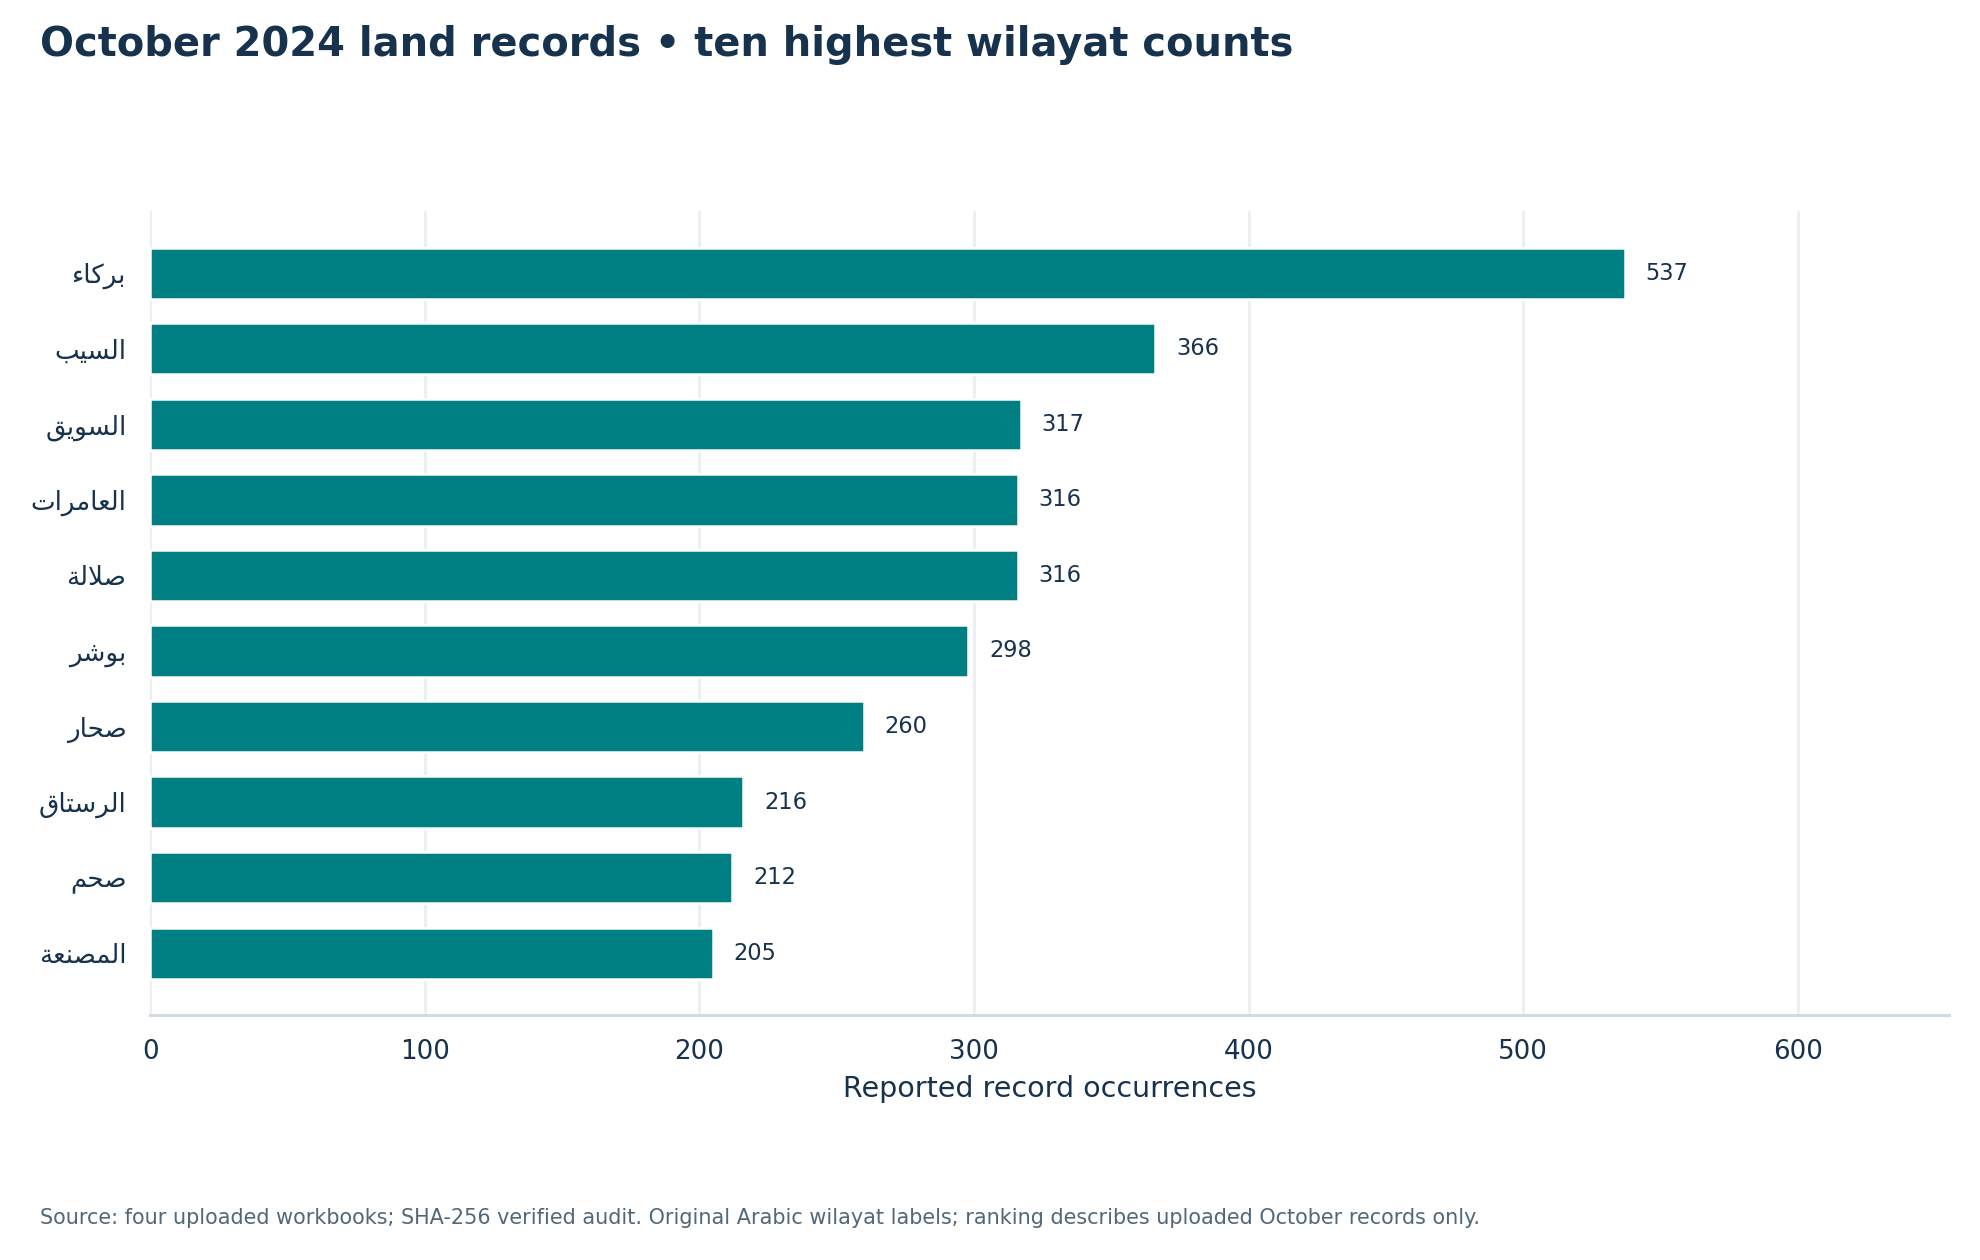

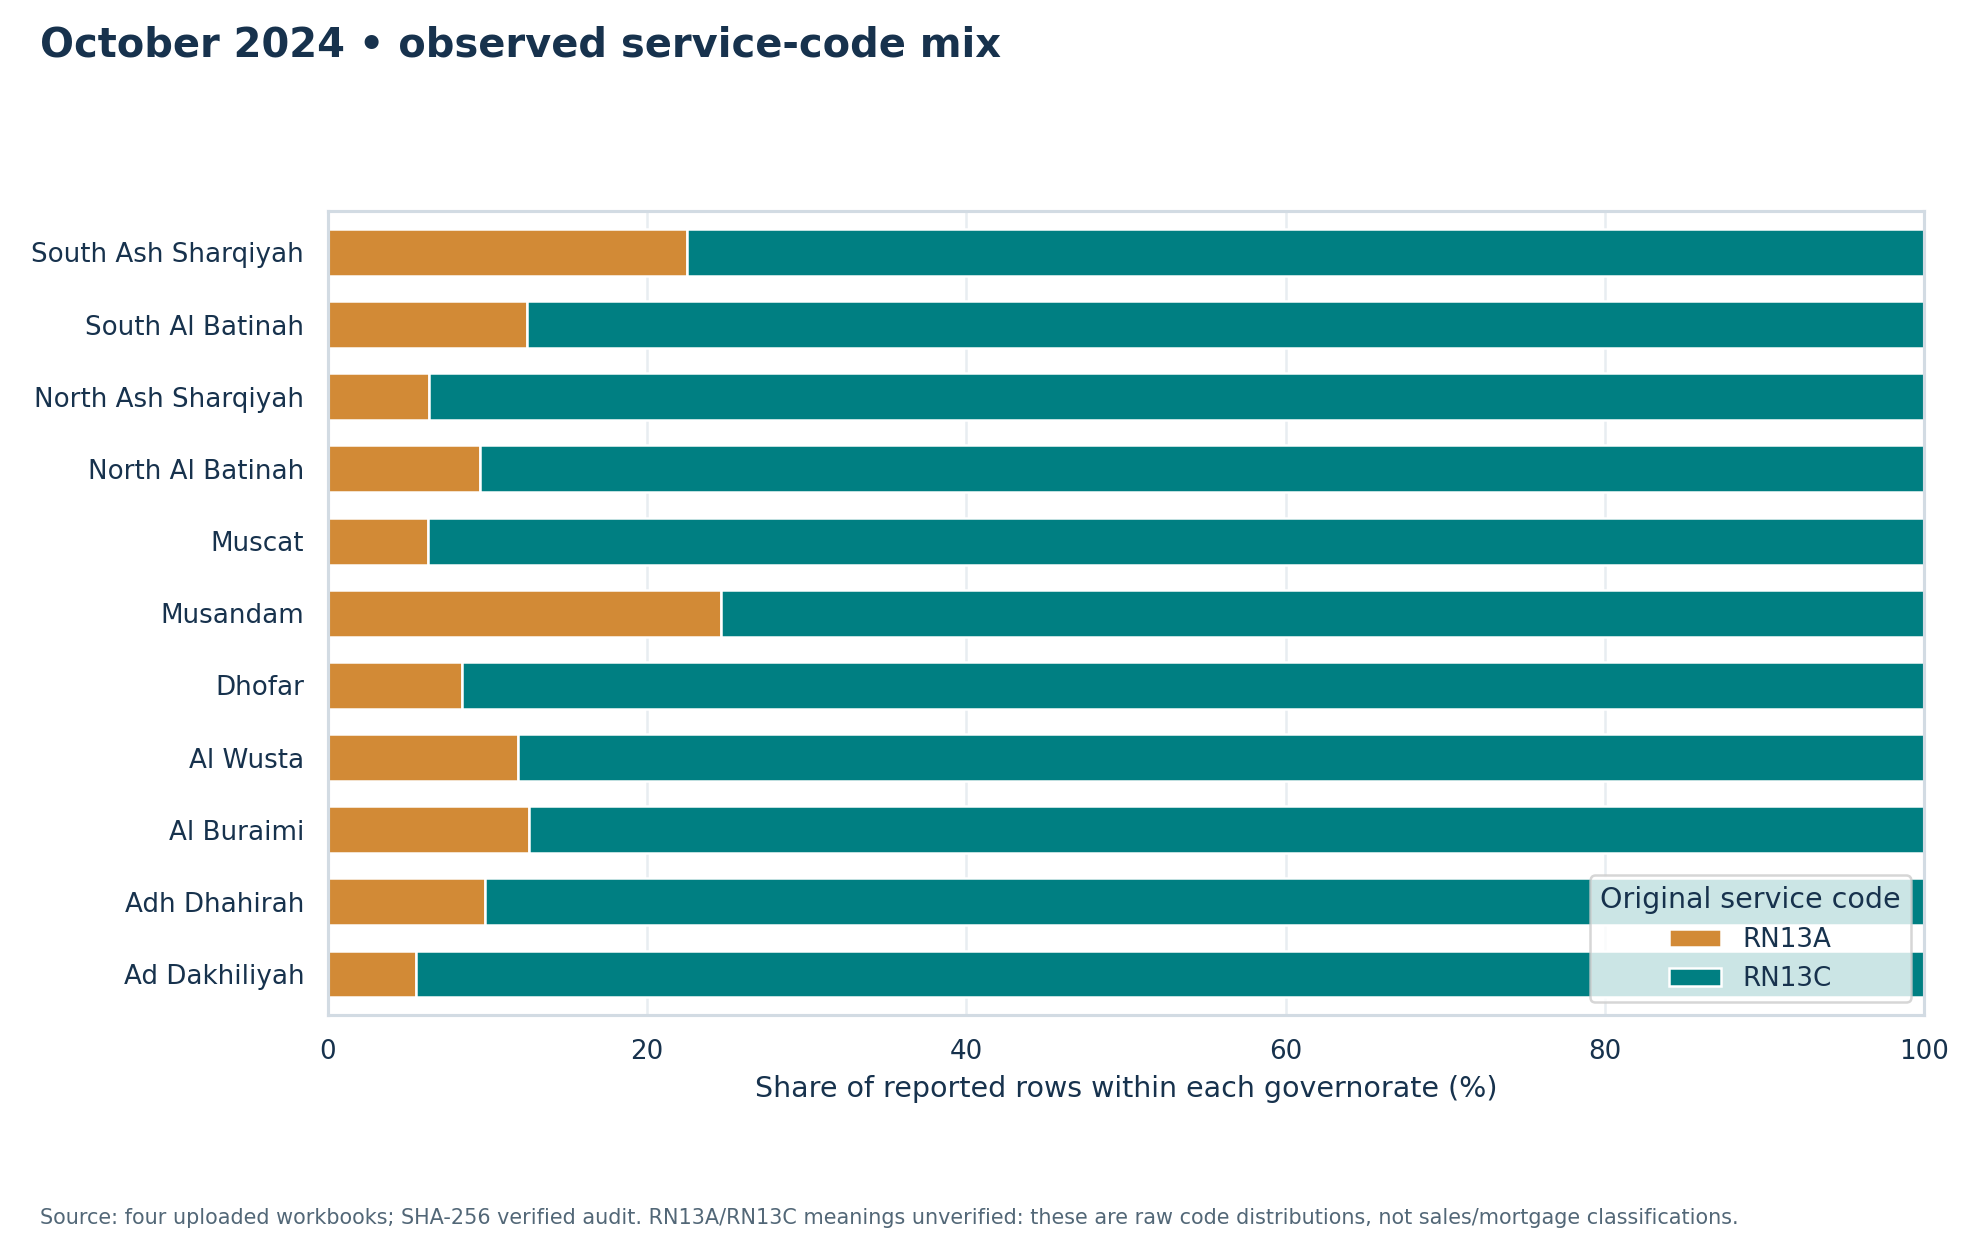

,dataset_id,period_id,service_sub_id,reported_record_count,cohort_record_count,share_pct
0,land_oct_2024,2024-10,RN13A,599,6024,9.94
1,land_oct_2024,2024-10,RN13C,5425,6024,90.06


,dataset_id,reported_record_count,records_in_repeated_groups,repeated_occurrences_after_first,repeated_group_share_pct,rows_removed,reported_amount_present_records,reported_amount_missing_records,monetary_unit_verified
0,land_dec_2022,5667,2600,1843,45.88,0,NaN,NaN,False
1,land_nov_2022,7501,3675,2629,48.99,0,NaN,NaN,False
2,land_oct_2024,6024,0,0,0.00,0,"5,657.00",367.00,False
3,muscat_brokerage_2025,9366,8174,6778,87.27,0,NaN,NaN,False


In [4]:
show_figure("land_2024_governorates")
show_figure("land_2024_wilayats")
show_figure("land_2024_service_codes")
display(tables["service_code_counts_2024"])
display(tables["data_quality_summary"])

## Buyer type and ownership attributes

Individual/Company are original source buyer labels. Owner bands are derived explicitly from NO_OF_OWNERS: 1, 2, 3, 4, or 5+ owners. Owner numbers are not a count of transactions, properties or buyers independently identified. Each panel describes its own supplied cohort.

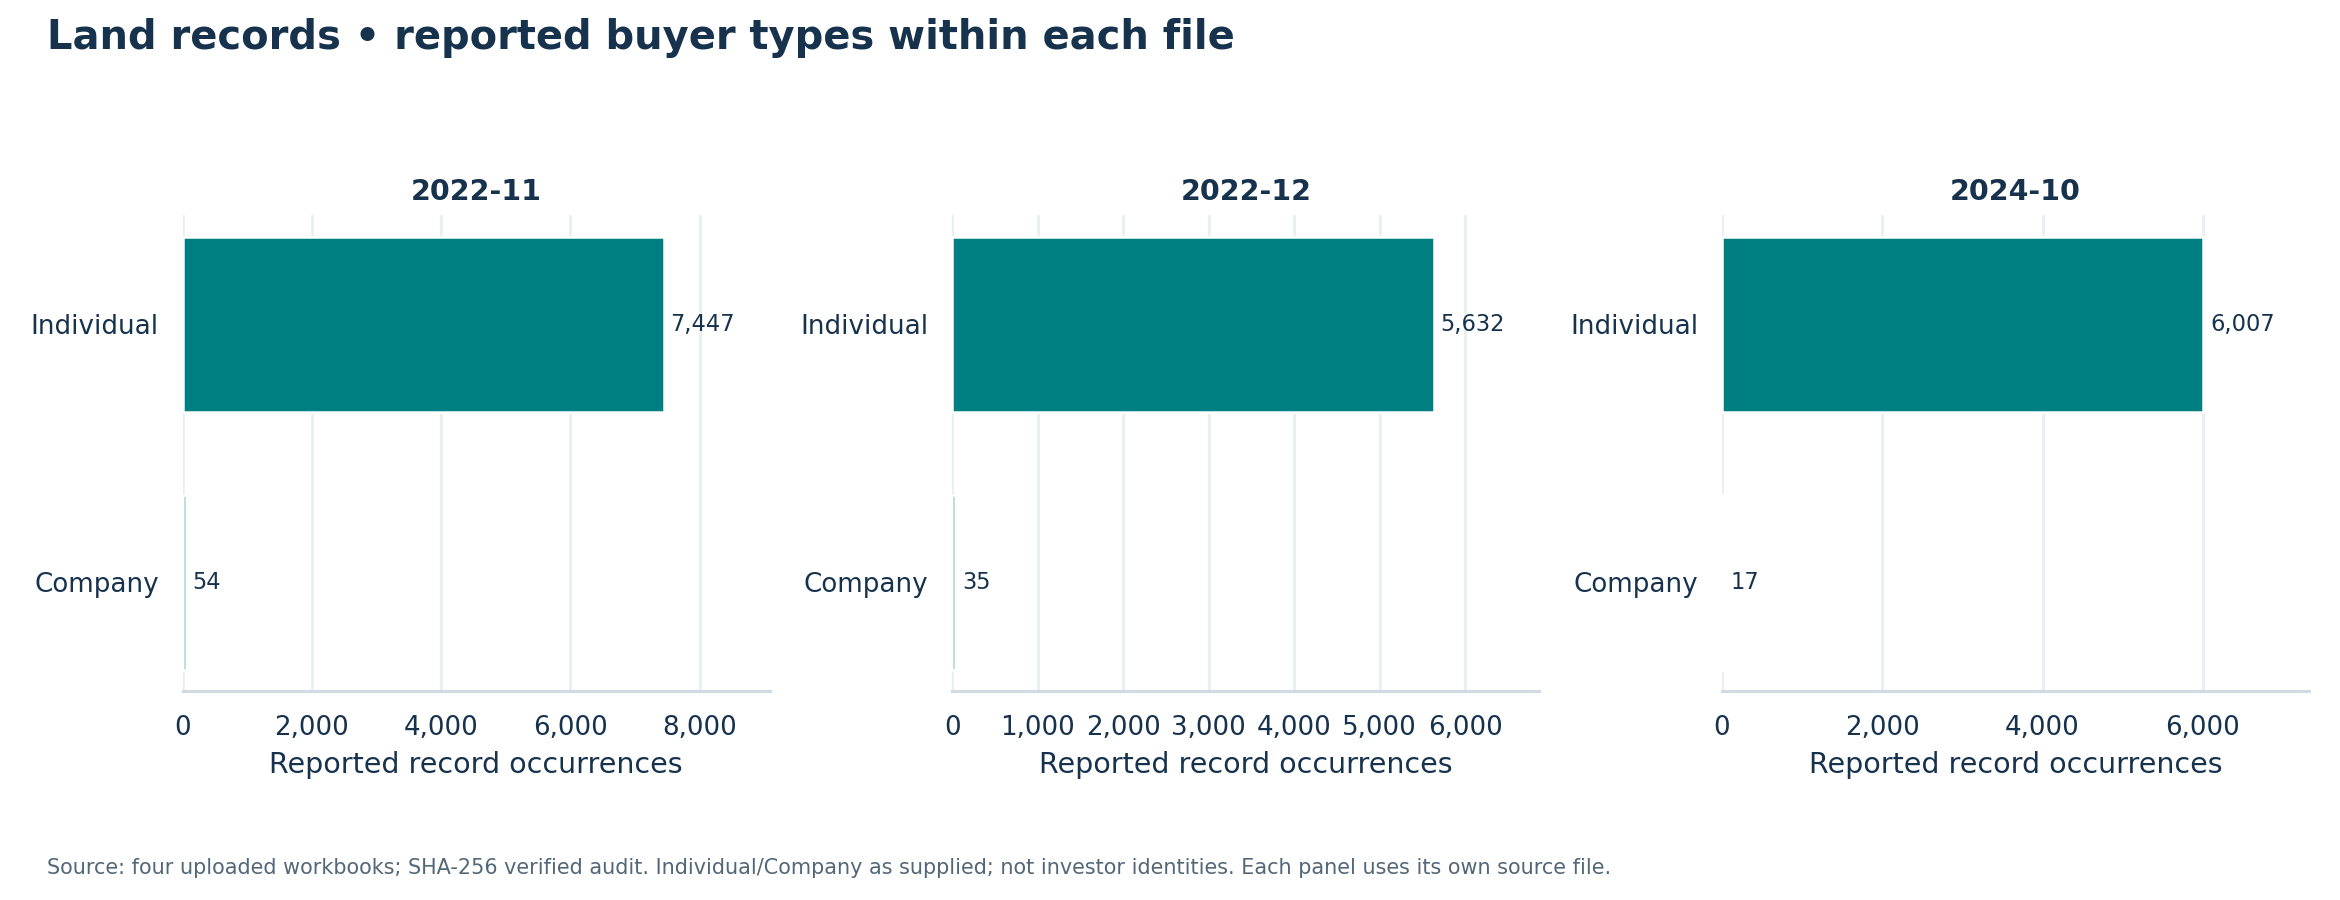

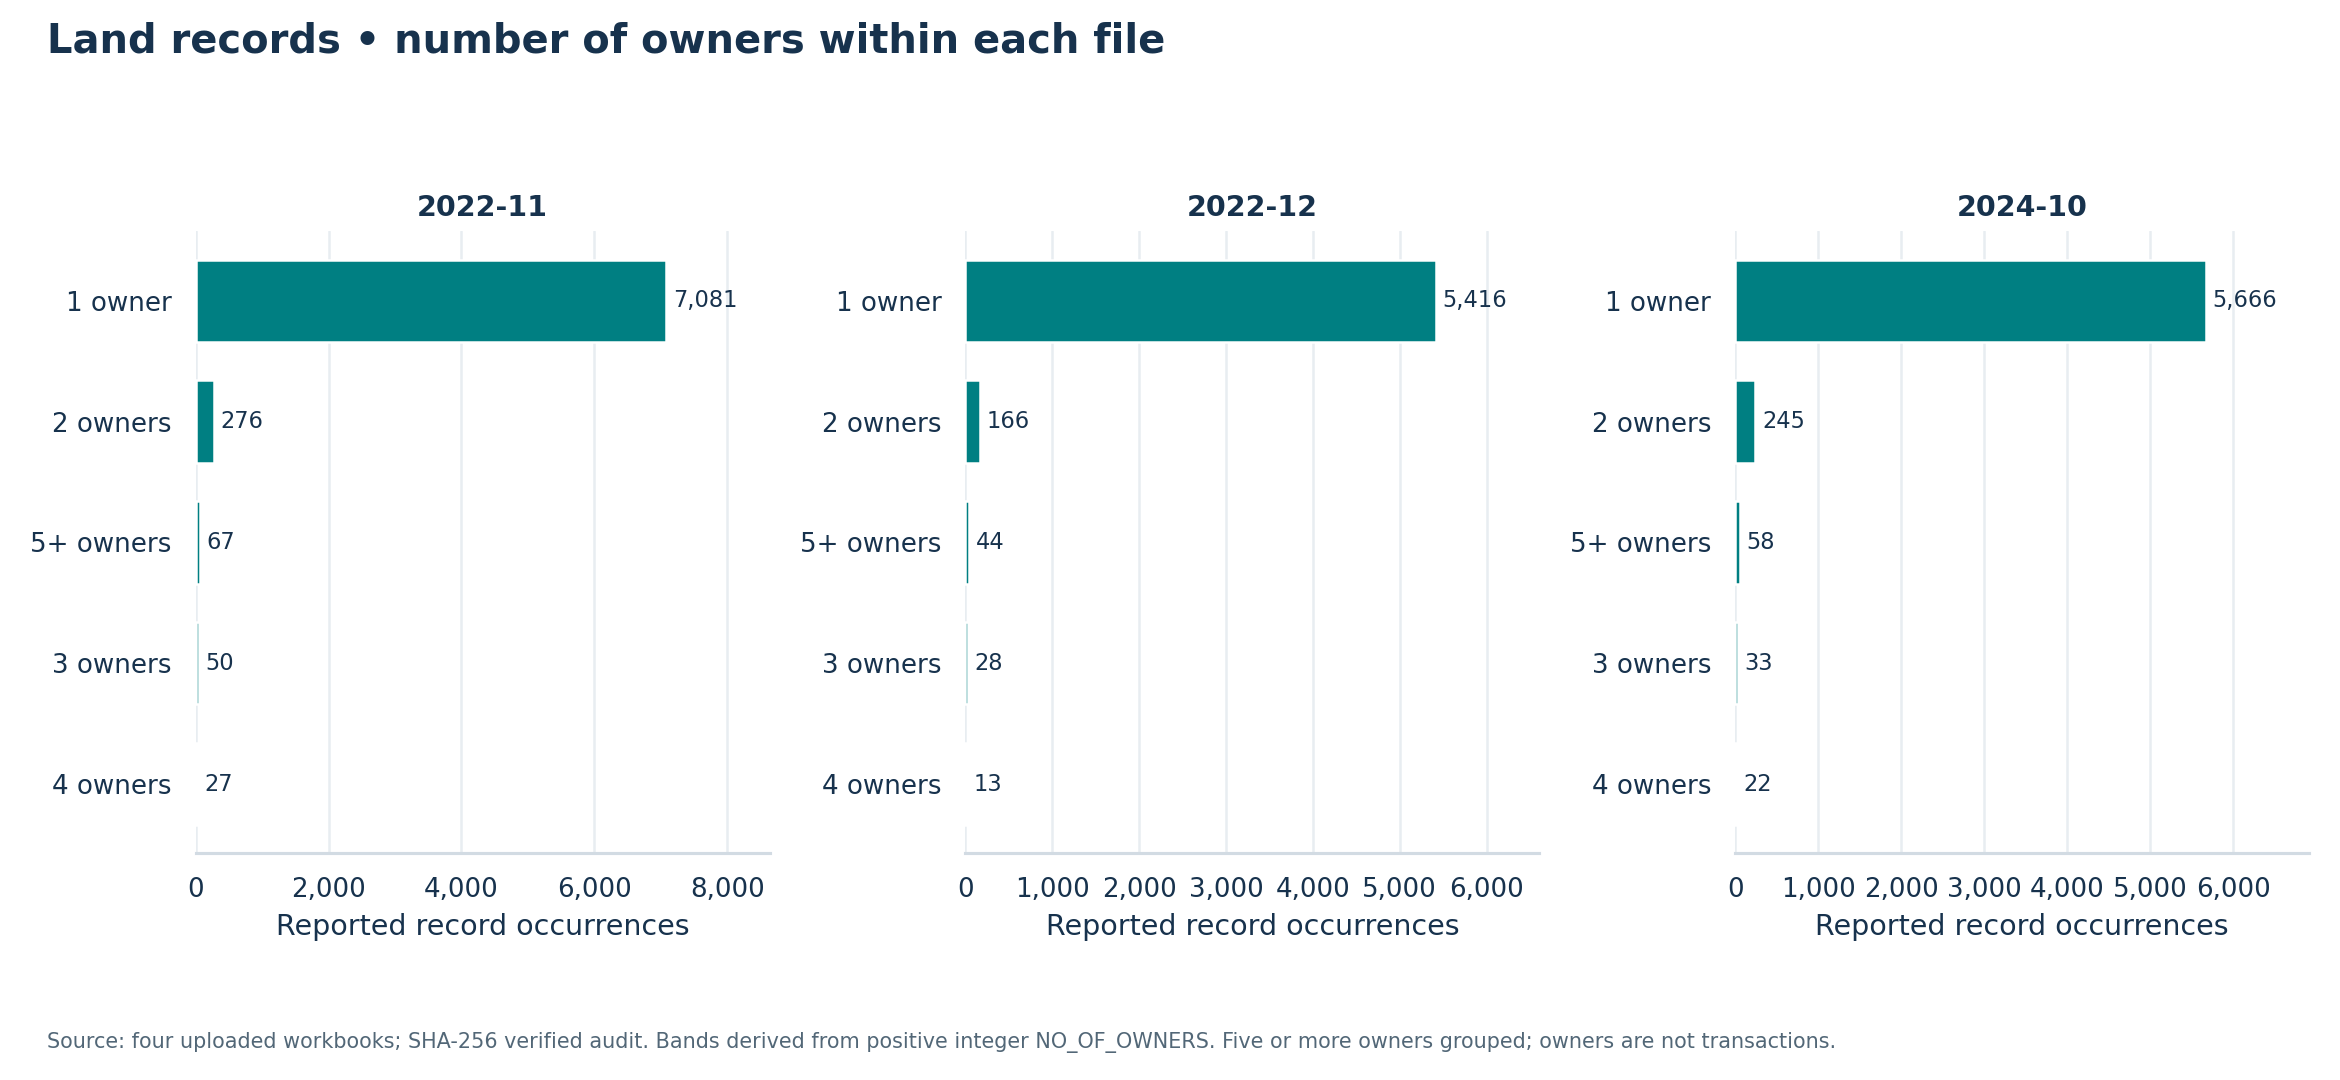

,dataset_id,scope_id,period_id,buyer_type,reported_record_count,cohort_record_count,share_pct
0,land_dec_2022,land_buy_sell_2022,2022-12,Company,35,5667,0.62
1,land_dec_2022,land_buy_sell_2022,2022-12,Individual,5632,5667,99.38
2,land_nov_2022,land_buy_sell_2022,2022-11,Company,54,7501,0.72
3,land_nov_2022,land_buy_sell_2022,2022-11,Individual,7447,7501,99.28
4,land_oct_2024,land_service_coded_2024,2024-10,Company,17,6024,0.28
5,land_oct_2024,land_service_coded_2024,2024-10,Individual,6007,6024,99.72


,dataset_id,scope_id,period_id,ownership_band,reported_record_count,cohort_record_count,share_pct
0,land_dec_2022,land_buy_sell_2022,2022-12,1 owner,5416,5667,95.57
1,land_dec_2022,land_buy_sell_2022,2022-12,2 owners,166,5667,2.93
2,land_dec_2022,land_buy_sell_2022,2022-12,3 owners,28,5667,0.49
3,land_dec_2022,land_buy_sell_2022,2022-12,4 owners,13,5667,0.23
4,land_dec_2022,land_buy_sell_2022,2022-12,5+ owners,44,5667,0.78
5,land_nov_2022,land_buy_sell_2022,2022-11,1 owner,7081,7501,94.40
6,land_nov_2022,land_buy_sell_2022,2022-11,2 owners,276,7501,3.68
7,land_nov_2022,land_buy_sell_2022,2022-11,3 owners,50,7501,0.67
8,land_nov_2022,land_buy_sell_2022,2022-11,4 owners,27,7501,0.36
9,land_nov_2022,land_buy_sell_2022,2022-11,5+ owners,67,7501,0.89


In [5]:
show_figure("land_buyer_types")
show_figure("land_ownership_bands")
display(tables["buyer_type_counts"])
display(tables["ownership_counts"])

## Muscat brokerage registrations

Use the brokerage-office sale-contract registration scope separately. January–September contains nine supplied months; the source's annual label does not imply full-year data. Property-use labels and property descriptions are different classification fields. Their raw Arabic categories are retained and should not be conflated with national property supply, prices or demand estimates.

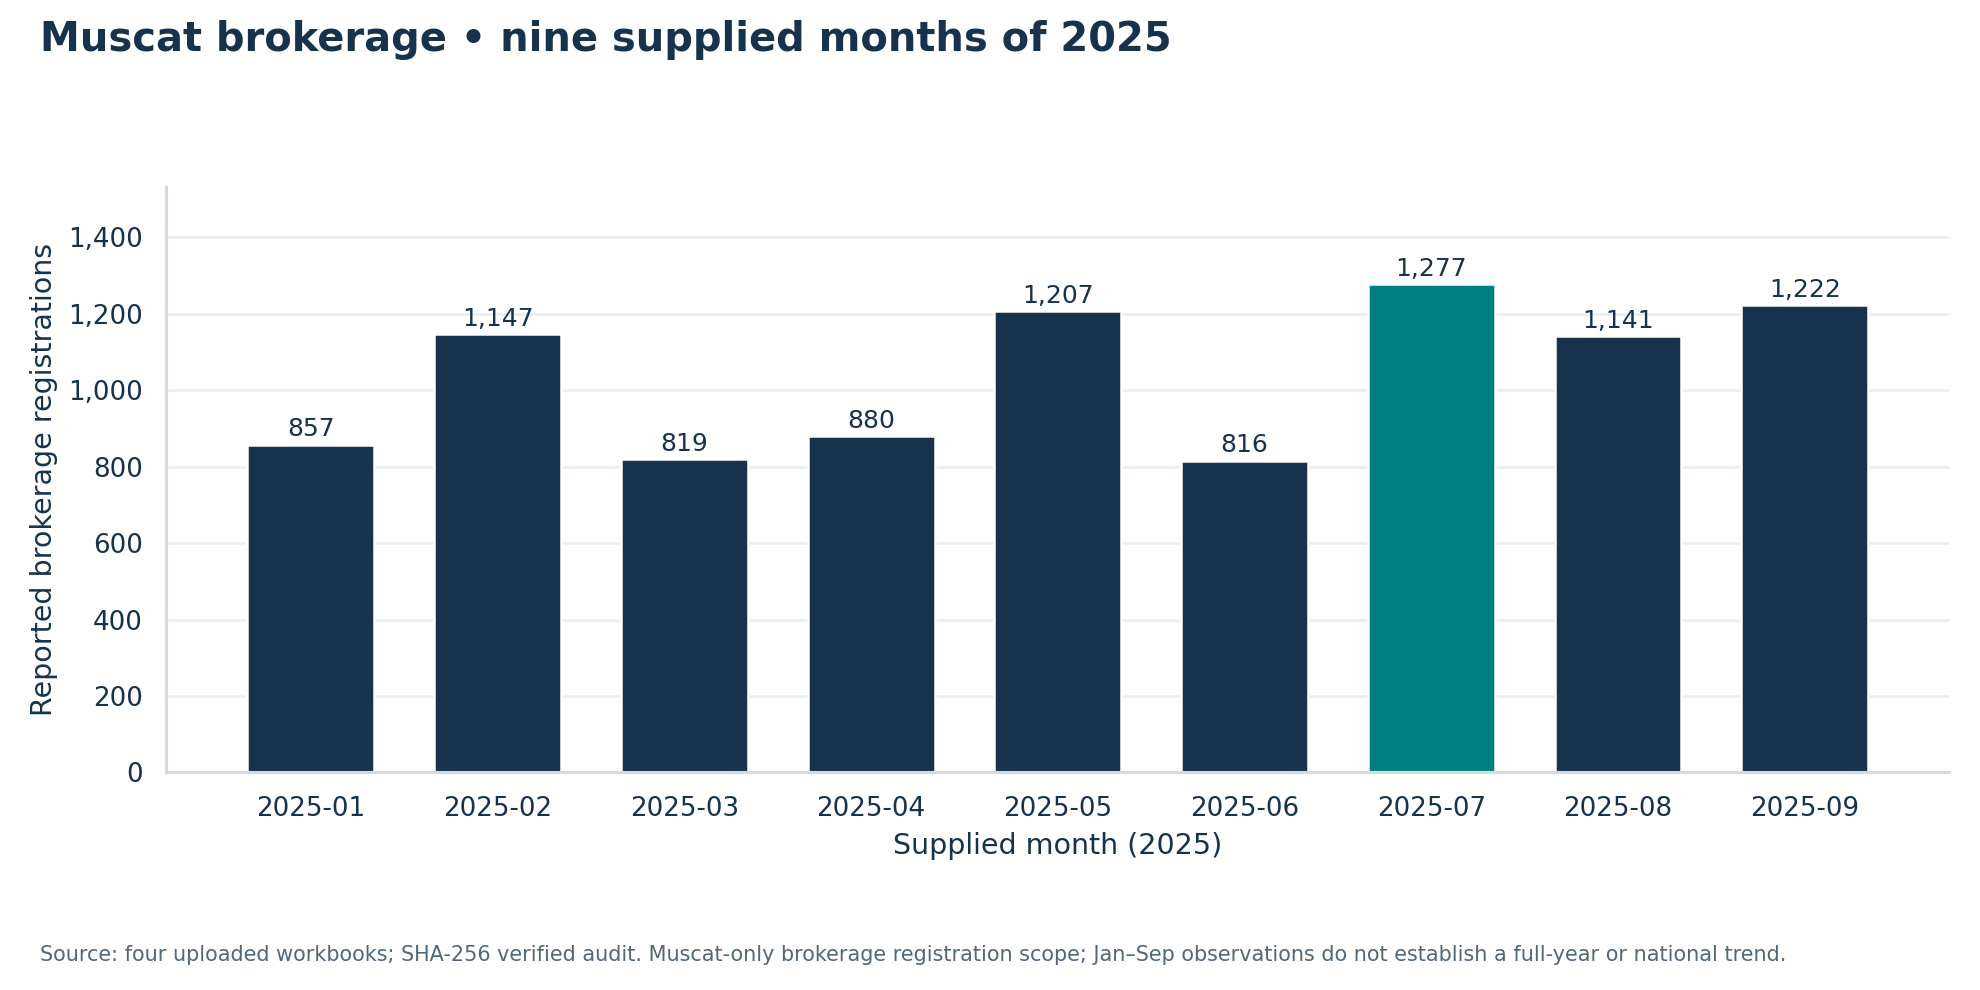

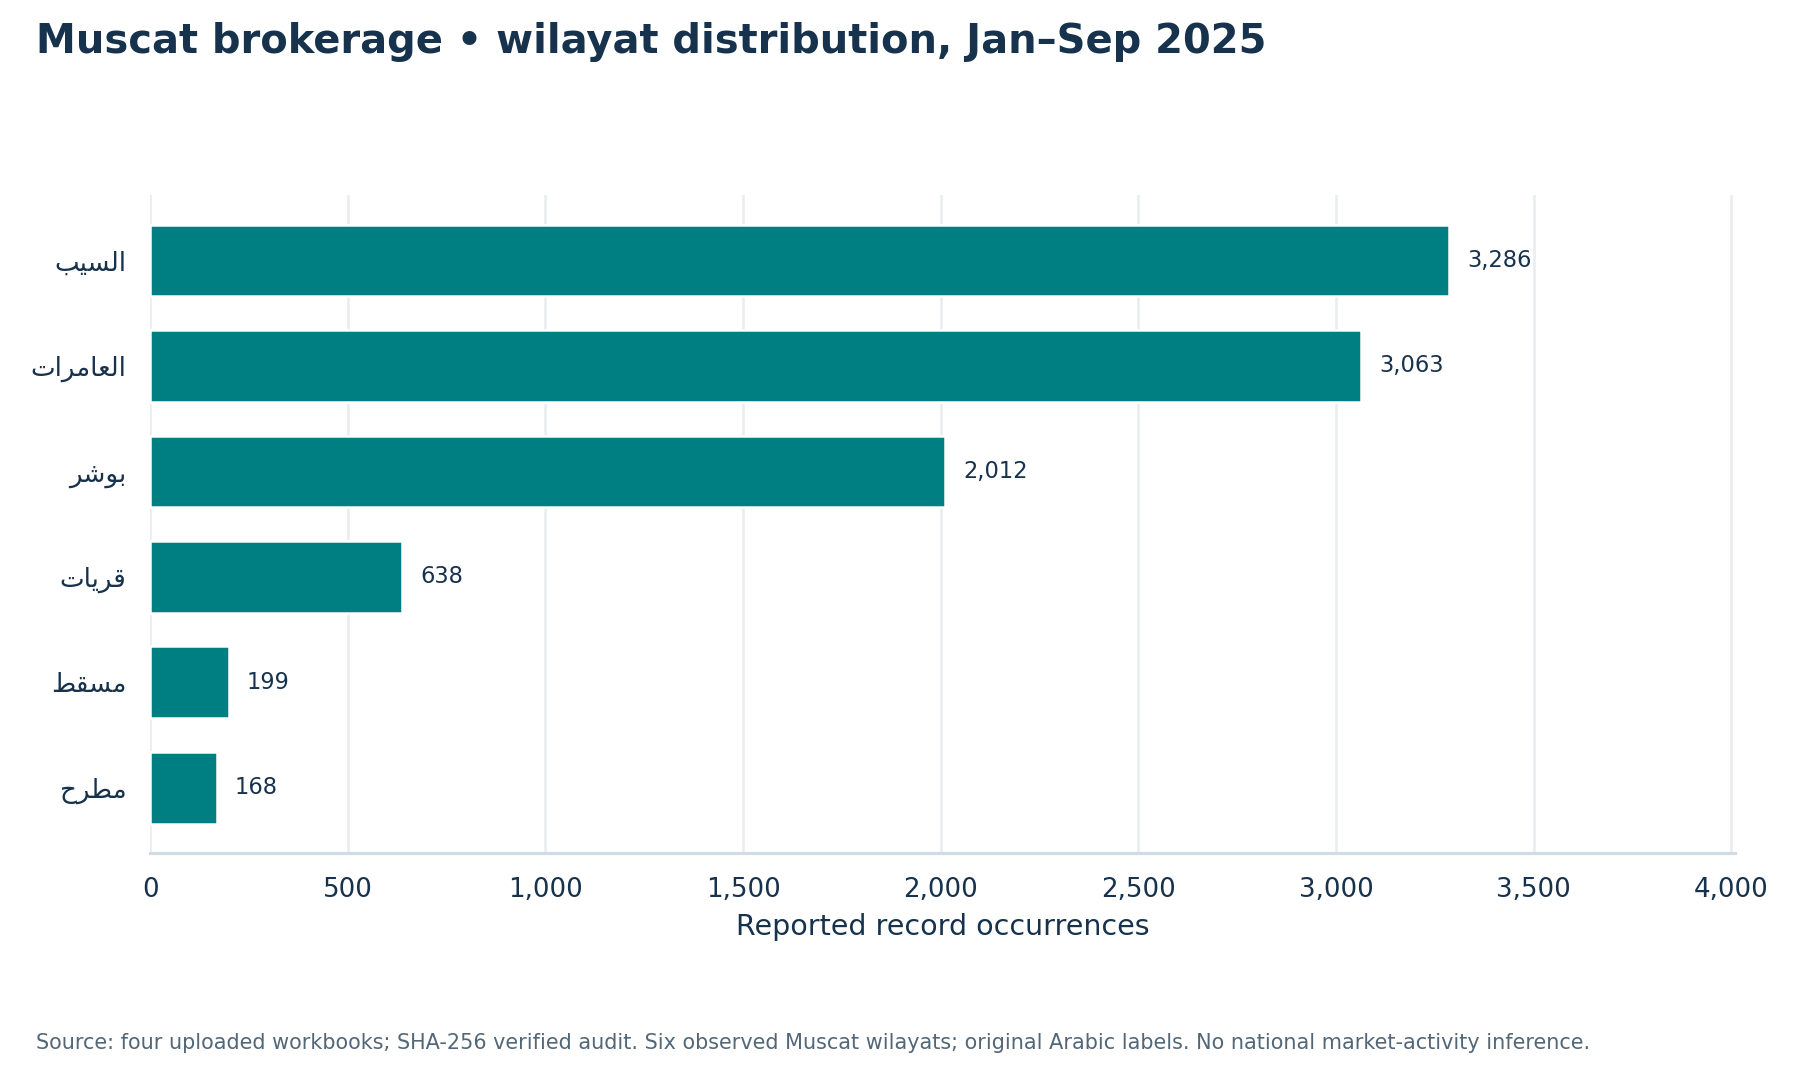

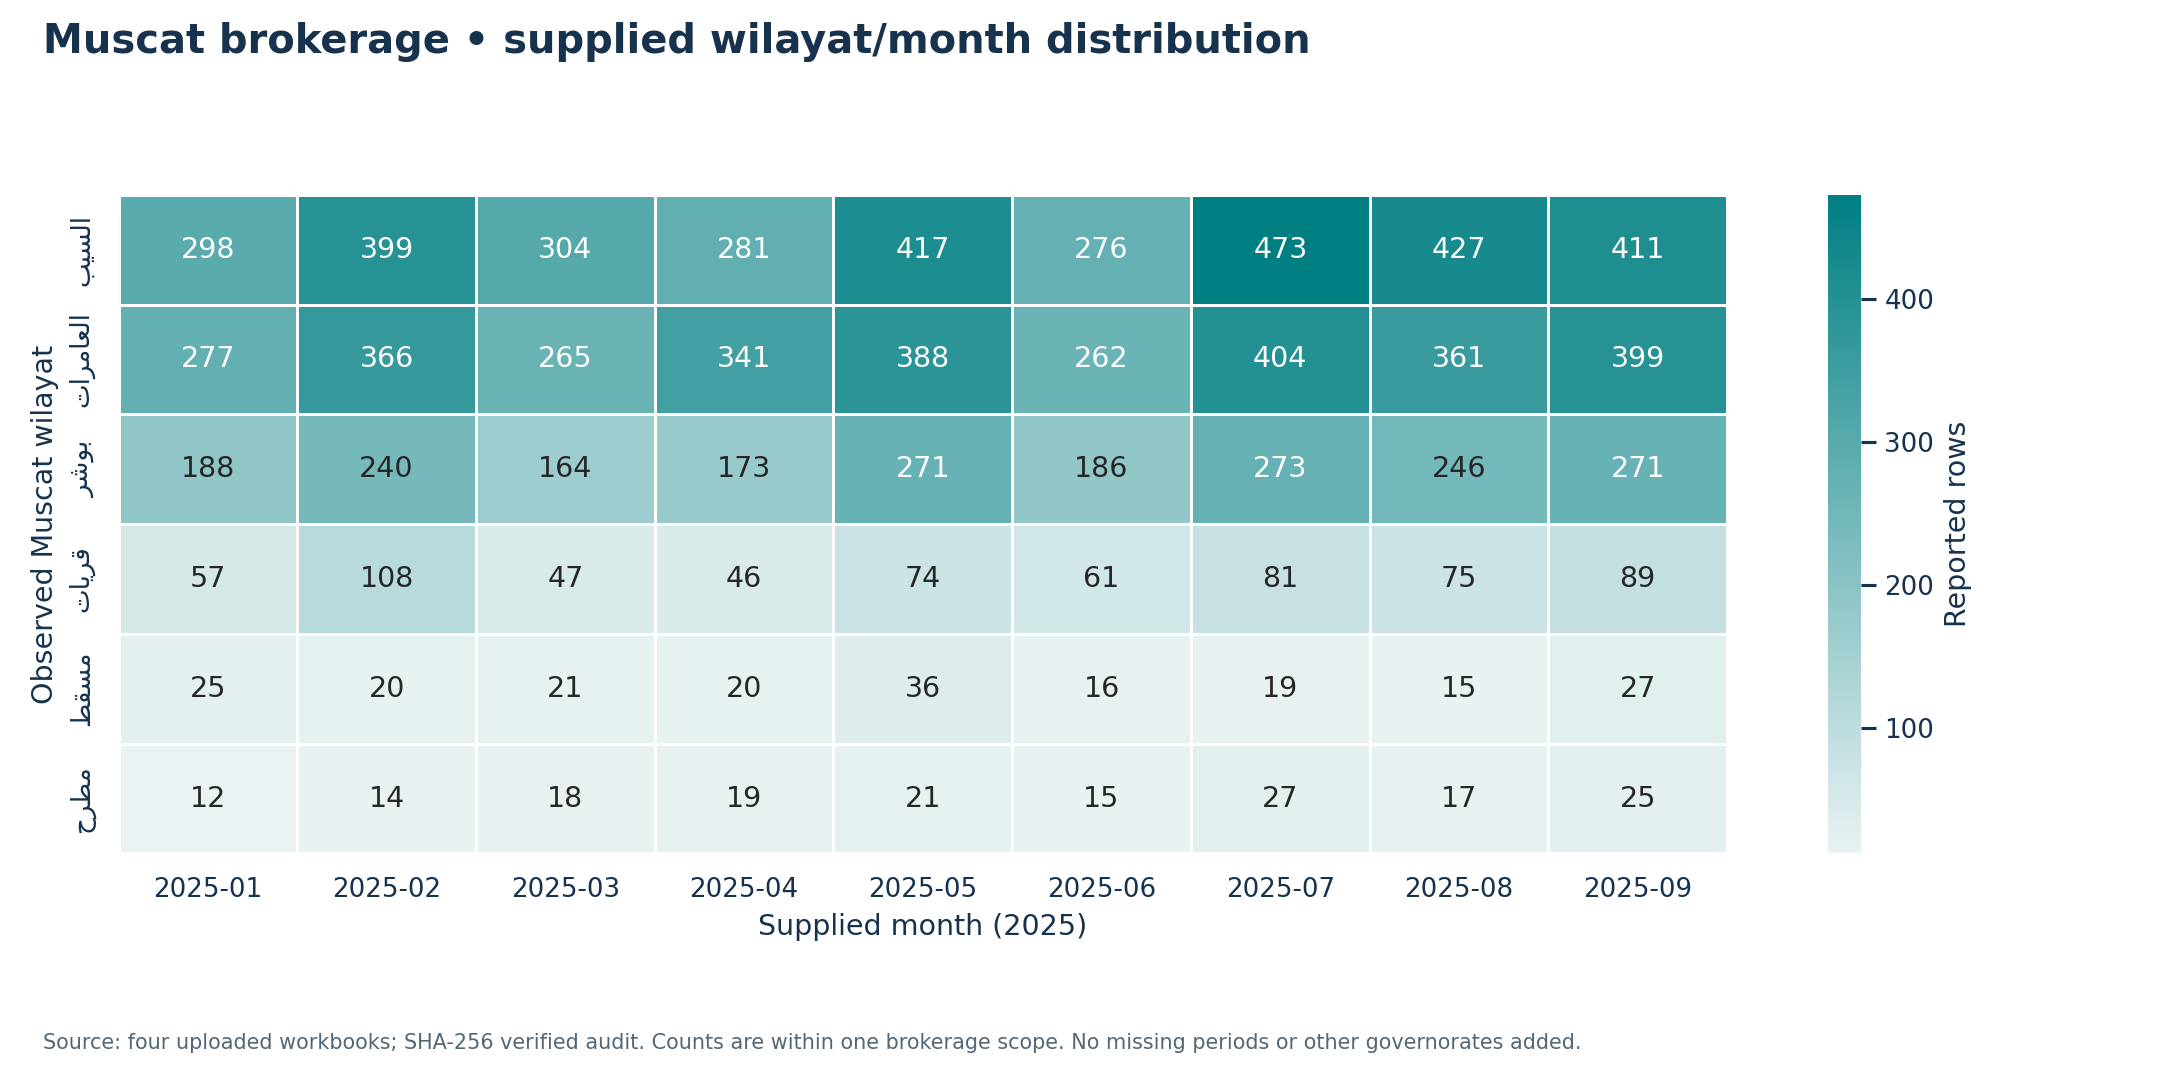

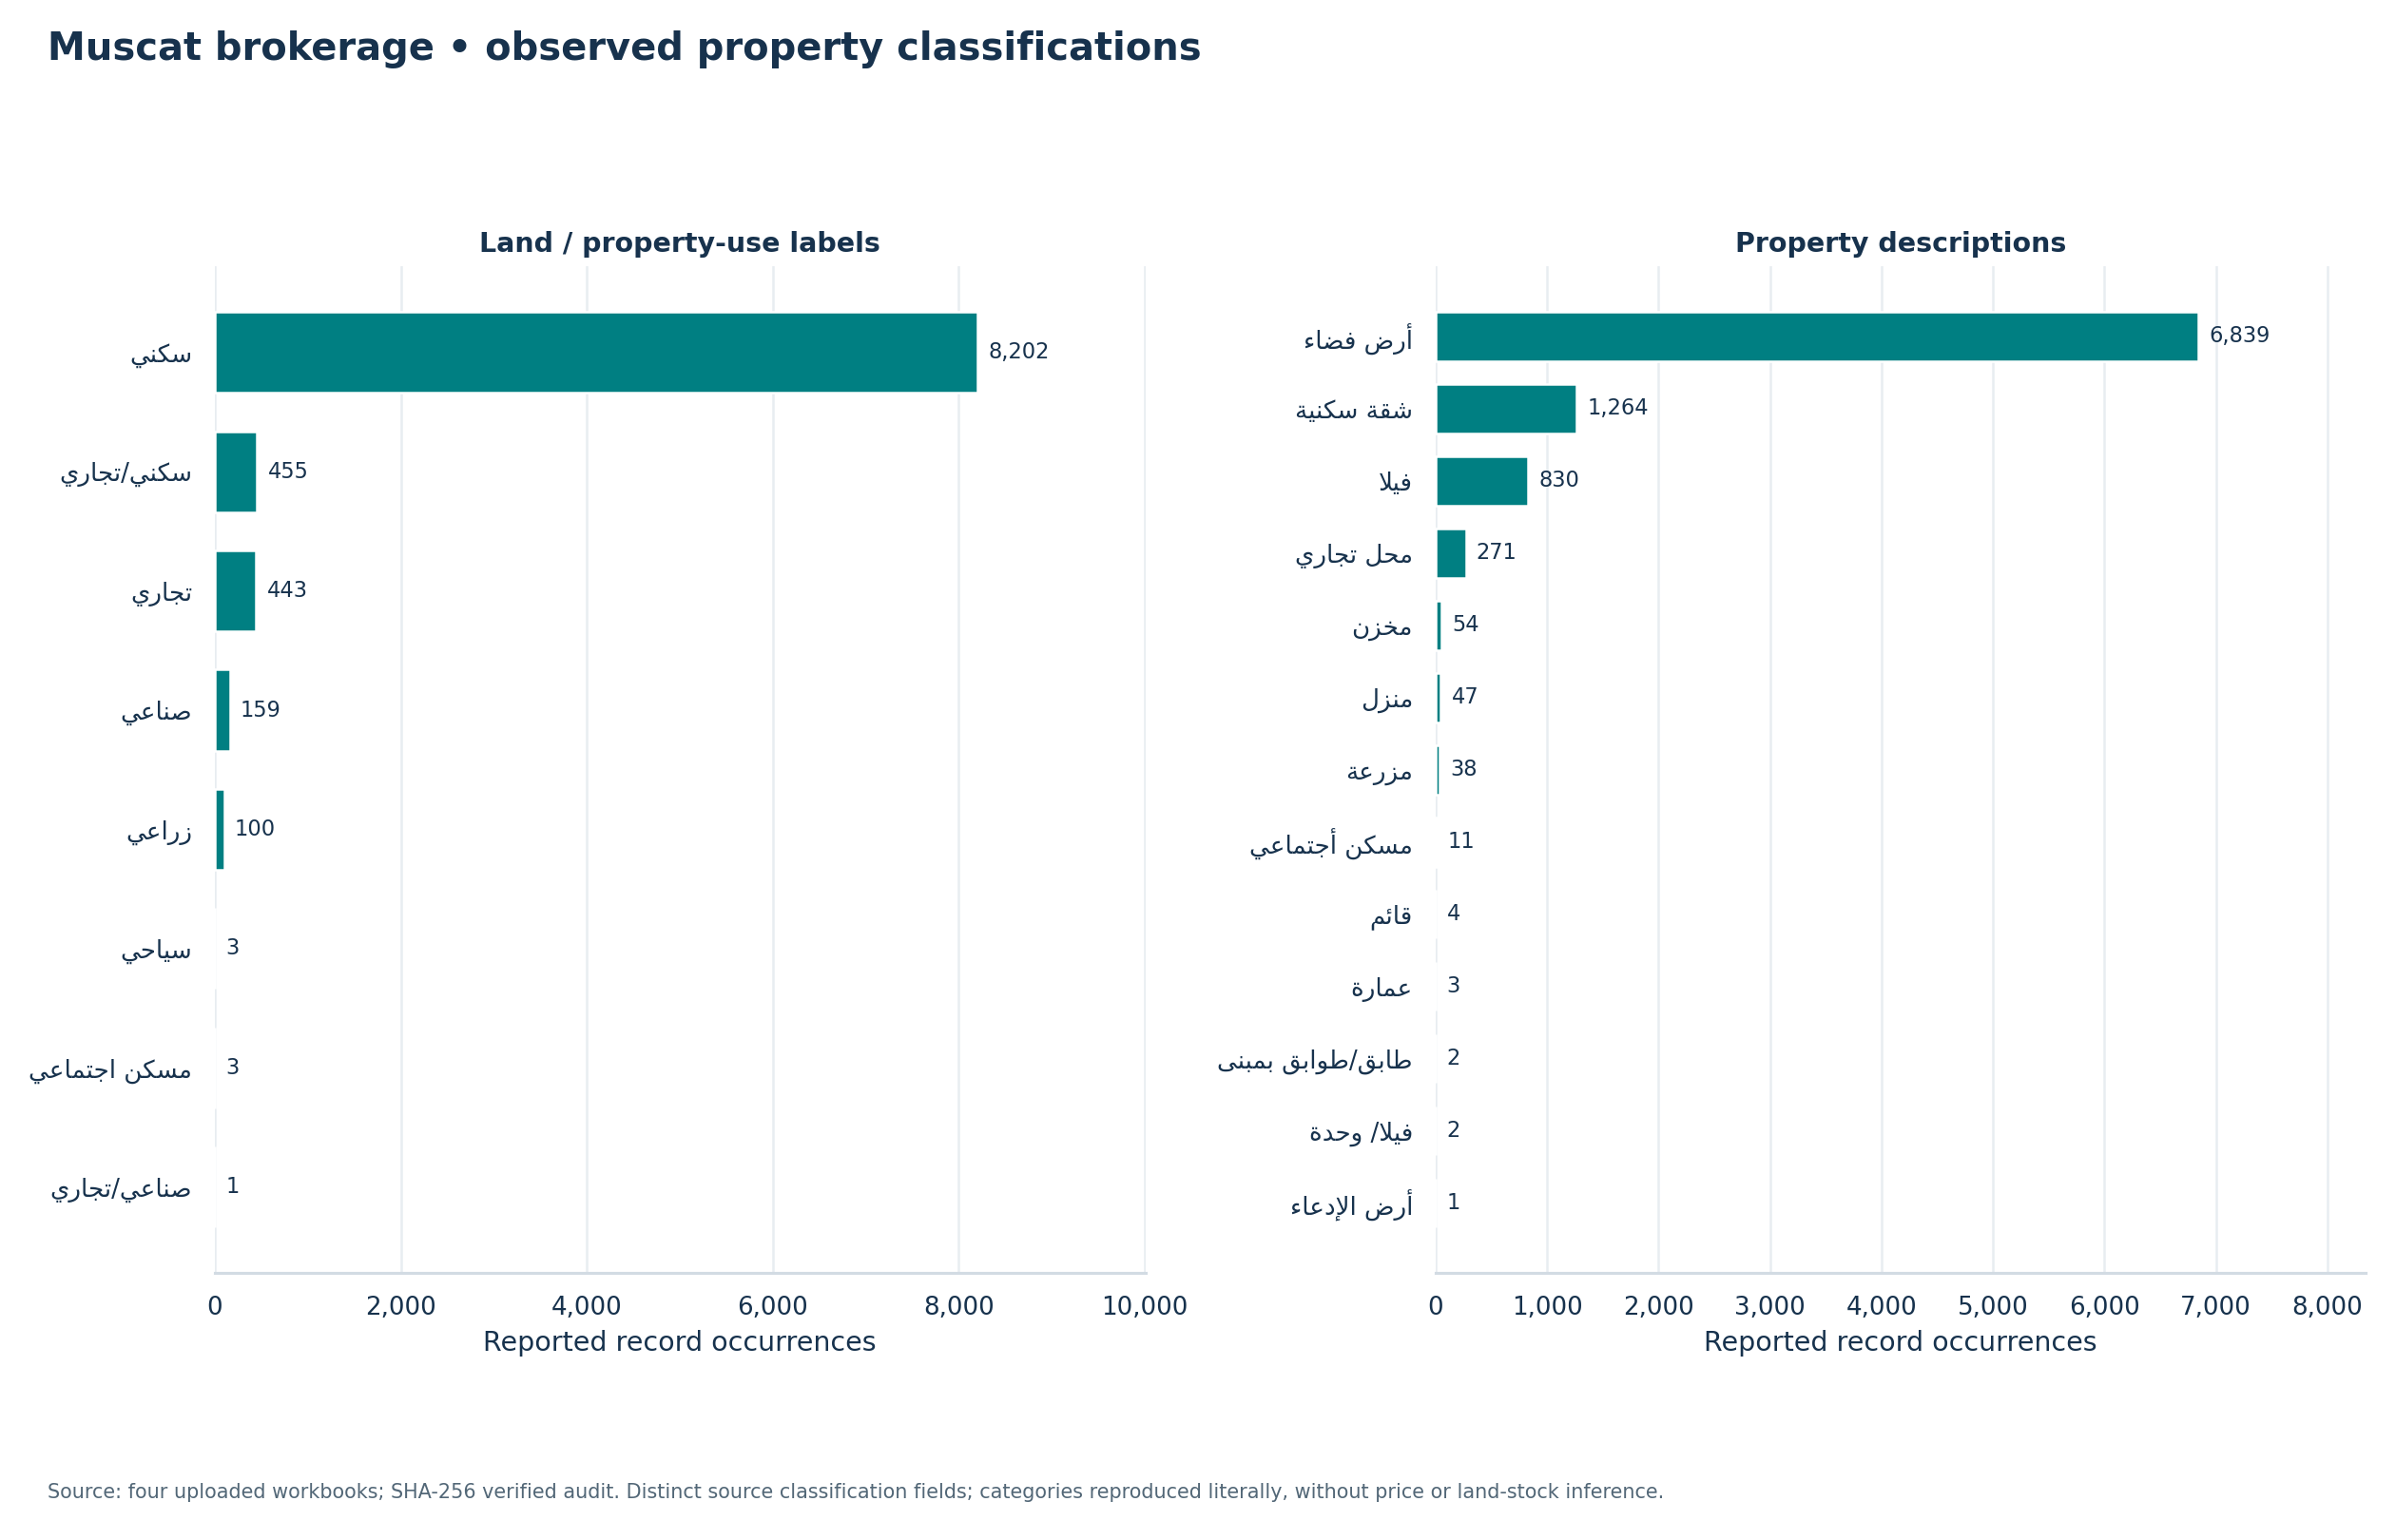

,dataset_id,scope_id,period_id,reported_record_count,cohort_record_count,share_pct
0,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-01,857,9366,9.15
1,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-02,1147,9366,12.25
2,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-03,819,9366,8.74
3,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-04,880,9366,9.40
4,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-05,1207,9366,12.89
5,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-06,816,9366,8.71
6,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-07,1277,9366,13.63
7,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-08,1141,9366,12.18
8,muscat_brokerage_2025,muscat_brokerage_registration_2025,2025-09,1222,9366,13.05


,dataset_id,scope_id,property_use_ar,reported_record_count,cohort_record_count,share_pct
0,muscat_brokerage_2025,muscat_brokerage_registration_2025,تجاري,443,9366,4.73
1,muscat_brokerage_2025,muscat_brokerage_registration_2025,زراعي,100,9366,1.07
2,muscat_brokerage_2025,muscat_brokerage_registration_2025,سكني,8202,9366,87.57
3,muscat_brokerage_2025,muscat_brokerage_registration_2025,سكني/تجاري,455,9366,4.86
4,muscat_brokerage_2025,muscat_brokerage_registration_2025,سياحي,3,9366,0.03
5,muscat_brokerage_2025,muscat_brokerage_registration_2025,صناعي,159,9366,1.70
6,muscat_brokerage_2025,muscat_brokerage_registration_2025,صناعي/تجاري,1,9366,0.01
7,muscat_brokerage_2025,muscat_brokerage_registration_2025,مسكن اجتماعي,3,9366,0.03


,dataset_id,scope_id,property_description_ar,reported_record_count,cohort_record_count,share_pct
0,muscat_brokerage_2025,muscat_brokerage_registration_2025,أرض الإدعاء,1,9366,0.01
1,muscat_brokerage_2025,muscat_brokerage_registration_2025,أرض فضاء,6839,9366,73.02
2,muscat_brokerage_2025,muscat_brokerage_registration_2025,شقة سكنية,1264,9366,13.50
3,muscat_brokerage_2025,muscat_brokerage_registration_2025,طابق/طوابق بمبنى,2,9366,0.02
4,muscat_brokerage_2025,muscat_brokerage_registration_2025,عمارة,3,9366,0.03
5,muscat_brokerage_2025,muscat_brokerage_registration_2025,فيلا,830,9366,8.86
6,muscat_brokerage_2025,muscat_brokerage_registration_2025,فيلا/ وحدة,2,9366,0.02
7,muscat_brokerage_2025,muscat_brokerage_registration_2025,قائم,4,9366,0.04
8,muscat_brokerage_2025,muscat_brokerage_registration_2025,محل تجاري,271,9366,2.89
9,muscat_brokerage_2025,muscat_brokerage_registration_2025,مخزن,54,9366,0.58


,dataset_id,scope_id,transaction_category_ar,reported_record_count,cohort_record_count,share_pct
0,muscat_brokerage_2025,muscat_brokerage_registration_2025,تسجيل عقد بيع من خلال مكاتب الوساطة العقارية,9366,9366,100.00


In [6]:
show_figure("muscat_monthly")
show_figure("muscat_wilayats")
show_figure("muscat_wilayat_monthly")
show_figure("muscat_property_categories")
display(tables["brokerage_monthly_counts"])
display(tables["brokerage_property_use"])
display(tables["brokerage_property_description"])
display(tables["brokerage_transaction_category"])

## Interpretation and next actions

The following findings are calculated from this run's tables, not hand-entered market claims. They establish patterns in uploaded records, not causal effects, investment returns or complete market trends. Read the methodology, missingness and repeated-row caveats before presenting rankings. Power BI import, relationships, DAX measures and page design are documented in `powerbi/EDA_MODEL.md`.

In [7]:
display(Markdown((ROOT / analysis["report_directory"] / "insights.md").read_text()))
print("Three monthly analytical fact totals:")
for name in ("fact_land_2022", "fact_land_2024", "fact_brokerage_2025"):
    print(name, len(tables[name]), "aggregate rows →", int(tables[name].reported_record_count.sum()), "source occurrences")
print("No annual/YoY, monetary, price, imputation or cross-scope market-total calculation is included.")

# Exploratory findings — supplied record occurrences

Analysis run `168665c92a8a2ff91598`; input audit `71008482abd46aa7f0bc`; base main `2c4237a` (merged PR #4).

**Interpretation:** counts describe uploaded source record occurrences. Completeness and unique transaction identity are unverified; repeated visible rows remain. The three scopes are never pooled into a national sales series. No monetary or price conclusion is calculated.

## Data used

| dataset_id | reported_record_count | first_record_date | last_record_date | observed_governorates | observed_wilayat_labels |
| --- | --- | --- | --- | --- | --- |
| land_dec_2022 | 5667 | 2022-12-04 | 2022-12-29 | 11 | 61 |
| land_nov_2022 | 7501 | 2022-11-01 | 2022-11-29 | 11 | 62 |
| land_oct_2024 | 6024 | 2024-10-01 | 2024-10-31 | 11 | 63 |
| muscat_brokerage_2025 | 9366 | 2025-01-02 | 2025-09-30 | 1 | 6 |

All four originals and every audited artifact match their pinned checksums. The land months represent all eleven modern governorates; the 2025 dataset covers Muscat only. Its nine months are not full-year coverage. Wilayat-label totals include nonstandard source labels, not a certified administrative inventory.

## 2022 land: two same-layout monthly snapshots

November has **7,501** reported rows and December **5,667**: a difference of **-1,834** (-24.45% relative to the November file). This is a supplied-file comparison, not verified market contraction or an annual trend.

- 2022-11: **Ad Dakhiliyah** has 1,301 rows (17.34% of that file).
- 2022-12: **Ad Dakhiliyah** has 1,075 rows (18.97% of that file).

November’s top two are Ad Dakhiliyah (1,301) and North Ash Sharqiyah (1,300), separated by 1 row(s); the rank alone does not establish a substantive market distinction. December’s geographic composition differs from November:

| governorate_en | november_records | december_records | november_share_pct | december_share_pct | share_change_percentage_points |
| --- | --- | --- | --- | --- | --- |
| Al Wusta | 105 | 294 | 1.40 | 5.19 | 3.79 |
| South Al Batinah | 1053 | 909 | 14.04 | 16.04 | 2.00 |
| Ad Dakhiliyah | 1301 | 1075 | 17.34 | 18.97 | 1.63 |
| North Al Batinah | 954 | 760 | 12.72 | 13.41 | 0.69 |
| Al Buraimi | 212 | 196 | 2.83 | 3.46 | 0.63 |
| South Ash Sharqiyah | 402 | 330 | 5.36 | 5.82 | 0.46 |
| Muscat | 960 | 734 | 12.80 | 12.95 | 0.15 |
| Musandam | 34 | 23 | 0.45 | 0.41 | -0.05 |
| Adh Dhahirah | 309 | 208 | 4.12 | 3.67 | -0.45 |
| Dhofar | 871 | 432 | 11.61 | 7.62 | -3.99 |
| North Ash Sharqiyah | 1300 | 706 | 17.33 | 12.46 | -4.87 |

Share shifts are percentage points, not property appreciation. Different source coverage or record-generation processes could affect these patterns. Two Dhofar rows labelled الساحل الشرقي are excluded only from wilayat rankings; all source rows remain in governorate totals. The complete observed wilayat table accompanies the top-ten charts.

## October 2024 land: separate service-coded snapshot

**North Al Batinah** has the highest supplied count (1,143; 18.97%). The top three are North Al Batinah, Muscat, South Al Batinah, with 3,325 rows (55.20% of the October file). This is a within-file concentration measure, not a cross-year trend or investment ranking.

| service_sub_id | reported_record_count | share_pct |
| --- | --- | --- |
| RN13A | 599 | 9.94 |
| RN13C | 5425 | 90.06 |

RN13A/RN13C are literal service codes with unverified meanings; neither is classified as sales, mortgages or another economic category. RE_VALUE contains 5,657 reported numbers and 367 blanks. Units and meanings are unresolved, so amounts are excluded from analytical facts and DAX calculations.

## Muscat brokerage: January–September 2025

**9,366** brokerage-office registrations are present. The highest supplied month is **2025-07**, with **1,277** rows, and the lowest is **2025-06**, with **816**. No missing month or year-end projection is created. Seasonality is not established by one partial year.

Wilayats **السيب and العامرات** together account for **6,349** rows (**67.79%**). This describes geographic distribution inside the brokerage scope; it does not establish national demand or investment returns.

The original residential-use label **سكني** appears on **8,202** rows (**87.57%**). The separate vacant-land description **أرض فضاء** appears on **6,839** (**73.02%**). Use and description are different fields and must not be added together as categories of one classification.

8 property-use labels, 13 property-description labels and 1 registration-category label(s) are supplied. Raw Arabic labels are preserved. Category distributions describe registered records, not the stock, supply or prices of all properties.

## Buyer and ownership attributes

| period_id | buyer_type | reported_record_count | share_pct |
| --- | --- | --- | --- |
| 2022-12 | Company | 35 | 0.62 |
| 2022-12 | Individual | 5632 | 99.38 |
| 2022-11 | Company | 54 | 0.72 |
| 2022-11 | Individual | 7447 | 99.28 |
| 2024-10 | Company | 17 | 0.28 |
| 2024-10 | Individual | 6007 | 99.72 |

Individual is the predominant reported buyer label in each file. Owner-count bands measure ownership multiplicity; they are not independent buyers, transaction counts or property prices. Five or more owners are grouped explicitly for readable distributions.

## Reliability and recommended decisions

1. Use regional and category distributions to prioritize further official data verification and investigation within each supplied scope. These files alone do not support investment recommendations.
2. Obtain complete comparable monthly series before trend, seasonality or annual-growth analysis. No 2020, 2021, 2023 or 2026 uploads exist; 2022 and 2024 are isolated land snapshots; 2025 brokerage is Muscat-only and partial year.
3. Confirm source URLs/licences, land-file publication dates, source completeness, transaction identity, service definitions and financial units before broader or monetary conclusions. Muscat’s embedded publication label predates some records.
4. Keep Power BI pages and measures separate by dataset definition. Count occurrences with SUM of the prepared count field; do not count aggregated fact rows or sum owner numbers as transactions.

Figures are generated by pandas/Matplotlib/Seaborn, and their chart-data tables are committed beside the Power BI facts. Methodology, transformations and provenance are documented in `docs/eda_methodology.md` and the source registry. All counts/shares reconcile; no originals are modified.


Three monthly analytical fact totals:
fact_land_2022 361 aggregate rows → 13168 source occurrences
fact_land_2024 257 aggregate rows → 6024 source occurrences
fact_brokerage_2025 403 aggregate rows → 9366 source occurrences
No annual/YoY, monetary, price, imputation or cross-scope market-total calculation is included.
